# 05 — Market Structure: Comparable Prices & Attribute Associations
**Dubai Real Estate Analytics V2 | Evidence-limited observational research**

**Scope:** RQ11 contemporaneous Ready–Off-Plan gaps; RQ10 price–area relationships; RQ12 bedroom and parking associations. All source records preserved. No causal premium, returns, rental yield, stock liquidity, or constant-quality inference. **Missing/unsupported estimates are `NaN`, never zero.**

All computations are based on the audited frozen DLD snapshot, using validated `src` modules. Population selection and matching decisions are made without inspecting the outcomes. The 2010–2025 historical P0/P1 framework remains intact, while the primary RQ11 comparison window is **2020–2025** and RQ10/RQ12 use **2015–2025**. This notebook requires pandas, numpy, scipy, statsmodels, matplotlib and pyarrow.

## 01. Research contract and reproducibility
**RQ11:** Off-Plan minus Ready log AED/sqm for transactions in observable shared strata. **RQ10:** conditional log-total-price size elasticity; AED/sqm is mathematically coupled to size. **RQ12:** adjusted categorical-bedroom and parking associations, only where variation is identifiable. Cohort restrictions and selection are part of the estimand. Decisions: SUPPORTED / QUALIFIED / INCONCLUSIVE / NOT ESTIMABLE / BLOCKED. Statistical significance cannot establish causality.

### Comparison populations and boundaries
P0 = eligible sales for descriptive provenance. P1 Core = built residential with positive price and area. P1 Strict = Core with zero publisher quality flags. P2 = P1 Strict with known community, registration and bedrooms. P3 = amenity-known and 2015–2025 (parking plus bedrooms), **not automatically Ready Units**. Price analyses use P1 Strict by default; P1 Core is a quality-policy sensitivity. Unknown identifiers and attributes remain unknown. Registration categories describe source registration, not completion, resale, or payment schedules.

In [1]:
from pathlib import Path
import sys, json, math, warnings, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import display
# VS Code notebooks may execute from the notebooks/ directory.
ROOT=Path.cwd().resolve()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
if not (ROOT/'src').exists(): raise FileNotFoundError('Launch from project root or notebooks/; src/ not found')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.loader import load_and_validate
from src.cleaning import clean_transactions, cohort_audit
from src.features import engineer_features
from src.config import SNAPSHOT_SHA256, COARSE_AREA_BANDS_SQM, research_paths
from src.statistics import ratio_coverage
PATHS=research_paths(ROOT); FIG=PATHS.figures; AGG=PATHS.aggregates; TABLES=PATHS.tables
for p in (FIG,AGG,TABLES):p.mkdir(parents=True,exist_ok=True)
SEED=2505; RNG=np.random.default_rng(SEED)
BASE_YEAR=2020; END_YEAR=2025; HIST_FROM=2015
REG_DESIGNS={
 'R0_type_year':['year','property_type_label'],
 'R1_area_year_type':['area_key','year','property_type_label'],
 'R2_area_year_type_size':['area_key','year','property_type_label','size_coarse'],
 'R3_area_year_type_rooms':['area_key','year','property_type_label','rooms_bucket'],
 'R4_area_year_type_rooms_size':['area_key','year','property_type_label','rooms_bucket','size_coarse'],
 'R5_area_quarter_type_rooms_size':['area_key','year_quarter','property_type_label','rooms_bucket','size_coarse'],
}
THRESHOLDS=(20,30,50); PRIMARY_MIN_N=30
REG_FALLBACK=('R4_area_year_type_rooms_size','R2_area_year_type_size','R1_area_year_type')
MIN_OVERLAP_EACH_SIDE_PCT=20.0; MIN_STRATA=10; MIN_EFF_STRATA=5.0
MIN_CLUSTER_COMMUNITIES=15; LOG_EPS=1e-12
warnings.filterwarnings('error',category=RuntimeWarning)
print('Root:',ROOT,' | Registered designs:',list(REG_DESIGNS))

Root: E:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2  | Registered designs: ['R0_type_year', 'R1_area_year_type', 'R2_area_year_type_size', 'R3_area_year_type_rooms', 'R4_area_year_type_rooms_size', 'R5_area_quarter_type_rooms_size']


In [2]:
raw,source,validation=load_and_validate(expected_sha256=SNAPSHOT_SHA256,strict=True)
cleaned=clean_transactions(raw,strict=False); f=engineer_features(cleaned)
p0=f.loc[f.eligible_market_activity & f.year.between(2010,2025)].copy()
p1_core=f.loc[f.eligible_residential_core & f.year.between(2010,2025)].copy()
p1=f.loc[f.eligible_residential_strict & f.year.between(2010,2025)].copy()
p2=f.loc[f.eligible_known_segment & f.year.between(2010,2025)].copy()
p3=f.loc[f.eligible_amenity_known & f.year.between(2015,2025)].copy()
assert len(raw)==len(f) and p0.transaction_id.is_unique
assert set(p1.transaction_id).issubset(set(p1_core.transaction_id))
assert set(p2.transaction_id).issubset(set(p1.transaction_id))
assert set(p3.transaction_id).issubset(set(p1.transaction_id))
source_manifest=pd.DataFrame([dict(sha256=source.sha256,rows=len(raw),columns=len(raw.columns),p0=len(p0),p1_core=len(p1_core),p1_strict=len(p1),p2=len(p2),p3=len(p3),source_path=source.path)])
cohort_reconciliation=cohort_audit(cleaned)
display(source_manifest,cohort_reconciliation)

,sha256,rows,columns,p0,p1_core,p1_strict,p2,p3,source_path
0,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,1382848,20,1134513,916748,901642,864170,712512,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...


,cohort_id,parent,input_n,retained_n,excluded_n
0,P0_ALL_SALES,raw source,1382848,1382848,0
1,P1_RESIDENTIAL_CORE,P0_ALL_SALES,1382848,1113177,269671
2,P1_STRICT,P1_RESIDENTIAL_CORE,1113177,1094417,18760
3,P2_KNOWN_SEGMENT,P1_STRICT,1094417,1041009,53408
4,P3_AMENITY_KNOWN,P1_STRICT,1094417,712512,381905
5,P4_2026_PROVISIONAL,P0_ALL_SALES,1382848,136035,1246813


### Prespecified acceptance contract
The 30-on-each-side threshold is a **candidate**, not proof of comparability. Prefer R4 only if both registration groups retain at least 20% of the declared P1 Strict window population, with ≥10 supported strata and effective strata ≥5; otherwise consider R2 then R1, without examining prices. R5 is a quarterly sensitivity only. Analyses may be marked NOT ESTIMABLE. Fixed area bands use `src.config` and the actual Notebook 02 `right=True` convention. Later model regressions require identifiable variation and cluster diagnostics. No outcome-driven model selection.

## 02. Source completeness, selection, and registration semantics
All retention rates require **explicit parent denominators**, including per-year and Unit/Villa differences. Project and building names are fallible text identifiers. An incomplete source field is never imputed.

,year,property_type_label,reg_type_label,attribute,n,known_n,known_pct
240,2025,Unit,Off-Plan,rooms_bucket,119449,119444,99.995814
241,2025,Unit,Off-Plan,has_parking,119449,119449,100.000000
242,2025,Unit,Off-Plan,area_id,119449,119449,100.000000
243,2025,Unit,Off-Plan,project_name,119449,119449,100.000000
244,2025,Unit,Off-Plan,building_name,119449,119449,100.000000
245,2025,Unit,Off-Plan,reg_type_label,119449,119449,100.000000
246,2025,Unit,Ready,rooms_bucket,43873,43822,99.883755
247,2025,Unit,Ready,has_parking,43873,43873,100.000000
248,2025,Unit,Ready,area_id,43873,43873,100.000000
249,2025,Unit,Ready,project_name,43873,32277,73.569166


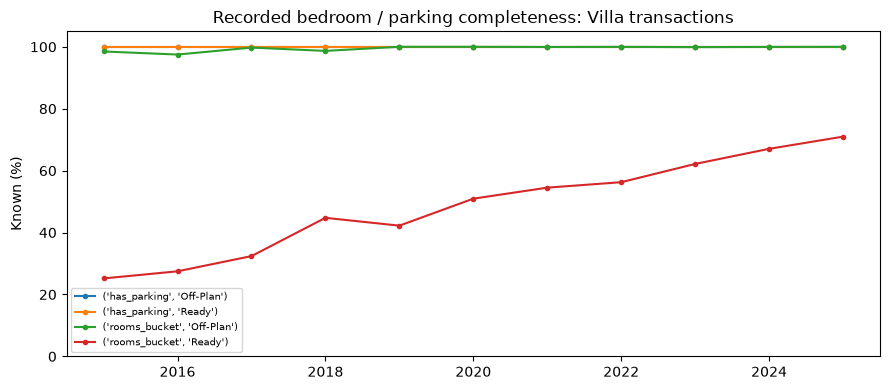

In [3]:
def size_bands(frame):
 out=frame.copy(); size=pd.Series(pd.NA,index=out.index,dtype='string')
 for typ,edges in COARSE_AREA_BANDS_SQM.items():
  k=out.property_type_label.eq(typ)
  labs=[f'{typ}:{i:02d}' for i in range(len(edges)-1)]
  size.loc[k]=pd.cut(out.loc[k,'area_sqm'],bins=list(edges),labels=labs,right=True).astype('string')
 out['size_coarse']=size
 out['area_key']=out['area_id'].astype('string')
 out['log_price']=np.log(out.price_aed.astype(float))
 out['log_area']=np.log(out.area_sqm.astype(float))
 out['log_psm']=np.log(out.price_per_sqm.astype(float))
 return out
r=size_bands(p1.loc[p1.year.between(2015,2025)].copy())
core=size_bands(p1_core.loc[p1_core.year.between(2015,2025)].copy())
r['year']=r.year.astype(int);core['year']=core.year.astype(int)
assert r['log_psm'].notna().all() and np.allclose(r.log_price-r.log_area,r.log_psm)
attr_cols=['rooms_bucket','has_parking','area_id','project_name','building_name','reg_type_label']
attr=[]
for (year,typ,reg),g in r.groupby(['year','property_type_label','reg_type_label'],observed=True,dropna=False):
 for a in attr_cols:
  attr.append(dict(year=year,property_type_label=typ,reg_type_label=reg,attribute=a,n=len(g),known_n=int(g[a].notna().sum()),known_pct=100*g[a].notna().mean()))
attribute_completeness=pd.DataFrame(attr)
display(attribute_completeness.query('year==2025').head(16))
fig,ax=plt.subplots(figsize=(9,4));s=attribute_completeness.query('attribute in ["rooms_bucket","has_parking"] and property_type_label=="Villa"')
for key,g in s.groupby(['attribute','reg_type_label']):
 ax.plot(g.year,g.known_pct,marker='.',label=str(key))
ax.set(title='Recorded bedroom / parking completeness: Villa transactions',ylabel='Known (%)',ylim=(0,105));ax.legend(fontsize=7);fig.tight_layout();fig.savefig(FIG/'05_attribute_completeness.png',dpi=140);plt.show()

In [4]:
procedure_diagnostics=(r.groupby(['year','property_type_label','reg_type_label','procedure_name_en','is_pre_registration'],dropna=False,observed=True).size().rename('n').reset_index())
assert procedure_diagnostics.n.sum()==len(r)
display(procedure_diagnostics.sort_values('n',ascending=False).head(15))
# Preserve conflicting process composition rather than equating Ready with resale.
registration_process_caveat='Ready/Off-Plan label is NOT a validated identical procedure, payment schedule or completion status.'

,year,property_type_label,reg_type_label,procedure_name_en,is_pre_registration,n
247,2025,Unit,Off-Plan,Sell - Pre registration,True,119233
222,2024,Unit,Off-Plan,Sell - Pre registration,True,91962
200,2023,Unit,Off-Plan,Sell - Pre registration,True,56050
257,2025,Unit,Ready,Sell,False,36477
180,2022,Unit,Off-Plan,Sell - Pre registration,True,34025
233,2024,Unit,Ready,Sell,False,33831
210,2023,Unit,Ready,Sell,False,26805
190,2022,Unit,Ready,Sell,False,19593
157,2021,Unit,Off-Plan,Sell - Pre registration,True,16377
54,2017,Unit,Off-Plan,Sell - Pre registration,True,16259


In [5]:
selection=[]
for (year,typ,reg),g in r.groupby(['year','property_type_label','reg_type_label'],dropna=False,observed=True):
 for attr in ['rooms_bucket','has_parking']:
  sel=g[attr].notna();known=g.loc[sel];missing=g.loc[~sel]
  selection.append(dict(year=year,property_type_label=typ,reg_type_label=reg,attribute=attr,parent_n=len(g),known_n=len(known),missing_n=len(missing),retained_pct=100*sel.mean(),median_area_known=known.area_sqm.median(),median_area_missing=missing.area_sqm.median(),median_psm_known=known.price_per_sqm.median(),median_psm_missing=missing.price_per_sqm.median()))
attribute_selection_bias=pd.DataFrame(selection)
assert (attribute_selection_bias.known_n+attribute_selection_bias.missing_n==attribute_selection_bias.parent_n).all()
display(attribute_selection_bias.query('year==2025 and property_type_label=="Villa"'))

,year,property_type_label,reg_type_label,attribute,parent_n,known_n,missing_n,retained_pct,median_area_known,median_area_missing,median_psm_known,median_psm_missing
84,2025,Villa,Off-Plan,rooms_bucket,9113,9112,1,99.989027,187.26,296.83,16202.898551,13942.573190
85,2025,Villa,Off-Plan,has_parking,9113,9113,0,100.000000,187.31,NaN,16202.898551,NaN
86,2025,Villa,Ready,rooms_bucket,6527,4633,1894,70.982074,209.07,594.58,16062.413951,11597.261649
87,2025,Villa,Ready,has_parking,6527,6527,0,100.000000,244.78,NaN,15015.974441,NaN


In [6]:
# A single group table is computed once per design; registration counts remain outcomes-blind.
REG_WINDOW=r.loc[r.year.between(BASE_YEAR,END_YEAR)&r.reg_type_label.isin(['Ready','Off-Plan'])].copy()
PARENT_REG=REG_WINDOW.groupby('reg_type_label').size().reindex(['Ready','Off-Plan'],fill_value=0)
DESIGN_FRAMES={};DESIGN_COUNTS={};feas=[]
for design,keys in REG_DESIGNS.items():
 frame=REG_WINDOW.dropna(subset=keys).copy()
 DESIGN_FRAMES[design]=frame
 ct=frame.groupby(keys+['reg_type_label'],observed=True).size().unstack('reg_type_label',fill_value=0).reindex(columns=['Ready','Off-Plan'],fill_value=0)
 DESIGN_COUNTS[design]=ct
 for t in THRESHOLDS:
  good=ct.Ready.ge(t)&ct['Off-Plan'].ge(t)
  hit=ct.loc[good]
  ready_n=int(hit.Ready.sum());off_n=int(hit['Off-Plan'].sum());pool=hit.sum(axis=1)
  w=pool/pool.sum() if pool.sum() else pool.astype(float)
  feas.append(dict(design=design,min_cell_n=t,matched_strata=len(hit),ready_matched_n=ready_n,offplan_matched_n=off_n,ready_feature_n=int((frame.reg_type_label=='Ready').sum()),offplan_feature_n=int((frame.reg_type_label=='Off-Plan').sum()),ready_parent_n=int(PARENT_REG['Ready']),offplan_parent_n=int(PARENT_REG['Off-Plan']),ready_parent_coverage_pct=ratio_coverage(ready_n,int(PARENT_REG['Ready'])),offplan_parent_coverage_pct=ratio_coverage(off_n,int(PARENT_REG['Off-Plan'])),ready_conditional_pct=ratio_coverage(ready_n,int((frame.reg_type_label=='Ready').sum())),offplan_conditional_pct=ratio_coverage(off_n,int((frame.reg_type_label=='Off-Plan').sum())),effective_strata=float(1/(w*w).sum()) if len(w) else np.nan,largest_stratum_pct=float(100*w.max()) if len(w) else np.nan))
registration_overlap_feasibility=pd.DataFrame(feas)
assert (registration_overlap_feasibility[['ready_parent_coverage_pct','offplan_parent_coverage_pct']].le(100+1e-8) | registration_overlap_feasibility[['ready_parent_coverage_pct','offplan_parent_coverage_pct']].isna()).all().all()
display(registration_overlap_feasibility.query('min_cell_n==30'))

,design,min_cell_n,matched_strata,ready_matched_n,offplan_matched_n,ready_feature_n,offplan_feature_n,ready_parent_n,offplan_parent_n,ready_parent_coverage_pct,offplan_parent_coverage_pct,ready_conditional_pct,offplan_conditional_pct,effective_strata,largest_stratum_pct
1,R0_type_year,30,12,212372,371687,212372,371687,212372,371687,100.000000,100.000000,100.000000,100.000000,5.711480,27.963271
4,R1_area_year_type,30,261,179130,331329,212372,371687,212372,371687,84.347277,89.141939,84.347277,89.141939,100.021569,3.403995
7,R2_area_year_type_size,30,663,142409,281433,212372,371687,212372,371687,67.056392,75.717741,67.056392,75.717741,286.975926,1.635043
10,R3_area_year_type_rooms,30,553,152048,303707,199014,371474,212372,371687,71.595126,81.710418,76.400655,81.757270,220.296362,2.009194
13,R4_area_year_type_rooms_size,30,693,122095,253849,199014,371474,212372,371687,57.491101,68.296443,61.349955,68.335604,275.879845,1.810908
16,R5_area_quarter_type_rooms_size,30,927,78267,172329,199014,371474,212372,371687,36.853728,46.364011,39.327384,46.390595,511.742235,0.855959


In [7]:
qual=registration_overlap_feasibility.query('min_cell_n==@PRIMARY_MIN_N').set_index('design')
def support_ok(d):
 z=qual.loc[d]
 return bool(z.matched_strata>=MIN_STRATA and z.effective_strata>=MIN_EFF_STRATA and z.ready_parent_coverage_pct>=MIN_OVERLAP_EACH_SIDE_PCT and z.offplan_parent_coverage_pct>=MIN_OVERLAP_EACH_SIDE_PCT)
SELECTED_REG=next((d for d in REG_FALLBACK if support_ok(d)),None)
feasibility_gate=pd.DataFrame([dict(rq='RQ11',population='P1 Strict; known registration; 2020–2025',selected_design=SELECTED_REG or 'NONE',decision='PASS' if SELECTED_REG else 'NO_GO',rule='First R4 then R2 then R1 satisfying 30 per side, >=10 strata, effective>=5, >=20% parent each side'),dict(rq='RQ10',population='P1 Strict; 2015–2025; Unit/Villa',selected_design='log_total_price',decision='PASS' if len(r)>=500 else 'NO_GO',rule='Positive finite prices/areas; supported type/year variation'),dict(rq='RQ12',population='P3 Ready Units; 2015–2025',selected_design='categorical attribute models after support',decision='CONDITIONAL',rule='Both categories sufficiently represented within supported communities/time/size')])
display(feasibility_gate)
print('Prespecified RQ11 design:',SELECTED_REG or 'NOT ESTIMABLE')

,rq,population,selected_design,decision,rule
0,RQ11,P1 Strict; known registration; 2020–2025,R4_area_year_type_rooms_size,PASS,First R4 then R2 then R1 satisfying 30 per sid...
1,RQ10,P1 Strict; 2015–2025; Unit/Villa,log_total_price,PASS,Positive finite prices/areas; supported type/y...
2,RQ12,P3 Ready Units; 2015–2025,categorical attribute models after support,CONDITIONAL,Both categories sufficiently represented withi...


Prespecified RQ11 design: R4_area_year_type_rooms_size


## 03. Observable residential structure
These descriptive summaries do **not** control unobserved property, delivery, or project quality. Raw differences and adjusted contrasts target different populations.

In [8]:
residential_structure=(r.groupby(['year','property_type_label','reg_type_label'],dropna=False,observed=True).agg(n=('transaction_id','size'),registered_value_aed=('price_aed','sum'),median_price_aed=('price_aed','median'),median_psm=('price_per_sqm','median'),median_area_sqm=('area_sqm','median'),mean_log_psm=('log_psm','mean')).reset_index())
assert residential_structure.n.sum()==len(r)
display(residential_structure.query('year==2025'))

,year,property_type_label,reg_type_label,n,registered_value_aed,median_price_aed,median_psm,median_area_sqm,mean_log_psm
40,2025,Unit,Off-Plan,119449,219456604854,1348888.0,19905.287714,72.27,9.927798
41,2025,Unit,Ready,43873,70687156055,1090000.0,14538.676608,77.35,9.604277
42,2025,Villa,Off-Plan,9113,34816499049,3529888.0,16202.898551,187.31,9.711247
43,2025,Villa,Ready,6527,32962319082,3650000.0,15015.974441,244.78,9.559612


,year,property_type_label,ready_n,offplan_n,log_gap,median_ready_psm,median_offplan_psm,gap_pct
20,2025,Unit,43873,119449,0.323521,14538.676608,19905.287714,38.198488
21,2025,Villa,6527,9113,0.151635,15015.974441,16202.898551,16.373541


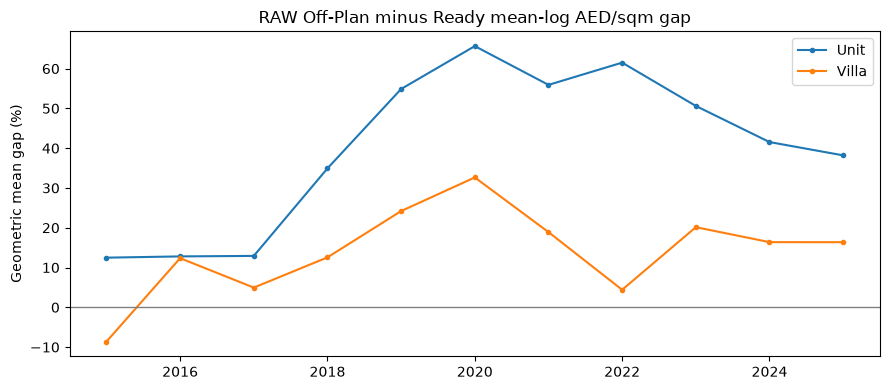

In [9]:
raw_gap=[]
for (yr,typ),g in r.loc[r.reg_type_label.isin(['Ready','Off-Plan'])].groupby(['year','property_type_label'],observed=True):
 a=g.loc[g.reg_type_label.eq('Ready'),'log_psm'];b=g.loc[g.reg_type_label.eq('Off-Plan'),'log_psm']
 raw_gap.append(dict(year=yr,property_type_label=typ,ready_n=len(a),offplan_n=len(b),log_gap=float(b.mean()-a.mean()) if len(a) and len(b) else np.nan,median_ready_psm=float(np.exp(a.median())) if len(a) else np.nan,median_offplan_psm=float(np.exp(b.median())) if len(b) else np.nan))
raw_registration_gaps=pd.DataFrame(raw_gap);raw_registration_gaps['gap_pct']=100*np.expm1(raw_registration_gaps.log_gap)
display(raw_registration_gaps.query('year==2025'))
fig,ax=plt.subplots(figsize=(9,4))
for k,g in raw_registration_gaps.groupby('property_type_label'):
 ax.plot(g.year,g.gap_pct,marker='.',label=k)
ax.axhline(0,c='gray',lw=1);ax.set(title='RAW Off-Plan minus Ready mean-log AED/sqm gap',ylabel='Geometric mean gap (%)');ax.legend();fig.tight_layout();fig.savefig(FIG/'05_raw_registration_gaps.png',dpi=140);plt.show()

In [10]:
registration_mix_diagnostics=(r.groupby(['year','property_type_label','reg_type_label','size_coarse','rooms_bucket'],dropna=False,observed=True).agg(n=('transaction_id','size'),median_area=('area_sqm','median'),median_psm=('price_per_sqm','median')).reset_index())
assert registration_mix_diagnostics.n.sum()==len(r)
display(registration_mix_diagnostics.sort_values('n',ascending=False).head(12))

,year,property_type_label,reg_type_label,size_coarse,rooms_bucket,n,median_area,median_psm
1205,2025,Unit,Off-Plan,Unit:02,1.0,38709,73.77,18091.286923
1196,2025,Unit,Off-Plan,Unit:00,0.0,28439,38.12,19539.614561
1066,2024,Unit,Off-Plan,Unit:02,1.0,27130,73.20,18148.692964
1055,2024,Unit,Off-Plan,Unit:00,0.0,17232,37.58,17996.828199
1212,2025,Unit,Off-Plan,Unit:03,2.0,16570,109.54,21080.297369
934,2023,Unit,Off-Plan,Unit:02,1.0,15816,73.41,20129.191874
1072,2024,Unit,Off-Plan,Unit:03,2.0,15389,108.10,21635.492681
1061,2024,Unit,Off-Plan,Unit:01,1.0,12741,59.34,18602.381417
1201,2025,Unit,Off-Plan,Unit:01,1.0,11567,58.68,20558.992347
1239,2025,Unit,Ready,Unit:02,1.0,10943,75.07,13454.936651


In [11]:
dist=[]
for key,g in r.groupby(['year','property_type_label','reg_type_label'],dropna=False,observed=True):
 dist.append(dict(year=key[0],property_type_label=key[1],reg_type_label=key[2],n=len(g),p10_log_psm=g.log_psm.quantile(.1),p50_log_psm=g.log_psm.median(),p90_log_psm=g.log_psm.quantile(.9),mean_log_psm=g.log_psm.mean(),log_psm_sd=g.log_psm.std()))
price_distribution_diagnostics=pd.DataFrame(dist)
display(price_distribution_diagnostics.query('year==2025'))

,year,property_type_label,reg_type_label,n,p10_log_psm,p50_log_psm,p90_log_psm,mean_log_psm,log_psm_sd
40,2025,Unit,Off-Plan,119449,9.536393,9.898741,10.366287,9.927798,0.326228
41,2025,Unit,Ready,43873,9.001990,9.584568,10.219024,9.604277,0.459710
42,2025,Villa,Off-Plan,9113,9.370356,9.692945,10.098439,9.711247,0.274539
43,2025,Villa,Ready,6527,8.991996,9.616870,10.046669,9.559612,0.442976


In [12]:
mix_project=[]
for (reg,typ),g in REG_WINDOW.groupby(['reg_type_label','property_type_label'],observed=True):
 for field in ['area_key','project_name','building_name']:
  z=g[field].dropna();freq=z.value_counts();p=freq/freq.sum() if len(freq) else pd.Series(dtype=float)
  mix_project.append(dict(reg_type_label=reg,property_type_label=typ,field=field,parent_n=len(g),known_n=len(z),known_pct=100*len(z)/len(g),distinct=int(len(freq)),known_label_hhi=float((p*p).sum()) if len(p) else np.nan,largest_known_label_pct=100*float(p.max()) if len(p) else np.nan))
comparison_concentration=pd.DataFrame(mix_project)
display(comparison_concentration)

,reg_type_label,property_type_label,field,parent_n,known_n,known_pct,distinct,known_label_hhi,largest_known_label_pct
0,Off-Plan,Unit,area_key,328633,328633,100.000000,60,0.044442,11.649469
1,Off-Plan,Unit,project_name,328633,328627,99.998174,1539,0.001772,0.974357
2,Off-Plan,Unit,building_name,328633,328633,100.000000,2201,0.001171,0.921697
3,Off-Plan,Villa,area_key,43054,43054,100.000000,24,0.132864,22.262740
4,Off-Plan,Villa,project_name,43054,43054,100.000000,206,0.011081,3.089144
5,Off-Plan,Villa,building_name,43054,0,0.000000,0,NaN,NaN
6,Ready,Unit,area_key,178471,178471,100.000000,66,0.049081,11.378319
7,Ready,Unit,project_name,178471,133796,74.967922,976,0.002532,1.439505
8,Ready,Unit,building_name,178471,178471,100.000000,2646,0.000867,0.395582
9,Ready,Villa,area_key,33901,33901,100.000000,94,0.048678,9.719477


### Handoff to adjusted comparisons
Raw group differences are affected by differences in area, bedroom completeness, project name coverage and registration procedures. **No raw-minus-adjusted difference is a causal decomposition.** The matched estimator uses only objectively supported strata and never substitutes a global citywide estimate for an unsupported group.

## 04. RQ11 — Contemporaneous Ready vs Off-Plan overlap prices
Primary estimand is the pooled-common-support-weighted difference in **mean log AED/sqm**, Off-Plan minus Ready, within matched strata. Group medians are a distinct sensitivity. Estimated differences are conditional observational associations; payment terms, completion, project quality, and financing are unobserved.

### Prespecified group threshold and reference distribution
Candidate groups are community/year/type/bedroom/area strata (R4), with R2 and R1 fallback if support fails. The chosen design and threshold are frozen using transaction counts only. The pooled overlap weight is `(ready_n + offplan_n)/sum(ready_n + offplan_n)`. Equal-stratum and side-weighted estimates may answer different questions.

In [13]:
registration_matching_decision=feasibility_gate.loc[feasibility_gate.rq.eq('RQ11')].copy()
if SELECTED_REG:
 selected_counts=DESIGN_COUNTS[SELECTED_REG]
 matched_mask=selected_counts.Ready.ge(PRIMARY_MIN_N)&selected_counts['Off-Plan'].ge(PRIMARY_MIN_N)
 selected_counts=selected_counts.loc[matched_mask].copy()
 selected_counts['pool_n']=selected_counts.Ready+selected_counts['Off-Plan']
 selected_counts['weight']=selected_counts.pool_n/selected_counts.pool_n.sum()
 assert selected_counts.weight.sum()>0 and np.isclose(selected_counts.weight.sum(),1)
else:
 selected_counts=pd.DataFrame(columns=['Ready','Off-Plan','pool_n','weight'])
registration_matched_cells=selected_counts.reset_index() if SELECTED_REG else pd.DataFrame()
display(registration_matching_decision,registration_matched_cells.head(8))

,rq,population,selected_design,decision,rule
0,RQ11,P1 Strict; known registration; 2020–2025,R4_area_year_type_rooms_size,PASS,First R4 then R2 then R1 satisfying 30 per sid...


reg_type_label,area_key,year,property_type_label,rooms_bucket,size_coarse,Ready,Off-Plan,pool_n,weight
0,232.0,2025,Unit,2.0,Unit:04,50,36,86,0.000229
1,317.0,2022,Unit,1.0,Unit:02,82,171,253,0.000673
2,317.0,2022,Unit,2.0,Unit:03,58,149,207,0.000551
3,317.0,2023,Unit,1.0,Unit:02,74,30,104,0.000277
4,330.0,2020,Unit,1.0,Unit:02,330,308,638,0.001697
5,330.0,2020,Unit,2.0,Unit:03,219,110,329,0.000875
6,330.0,2020,Unit,2.0,Unit:04,292,145,437,0.001162
7,330.0,2020,Unit,3.0,Unit:05,259,95,354,0.000942


,reg_type_label,parent_n,matched_n,coverage_pct
0,Ready,212372,122095,57.491101
1,Off-Plan,371687,253849,68.296443


,reg_type_label,in_match,n
0,Off-Plan,False,117838
1,Off-Plan,True,253849
2,Ready,False,90277
3,Ready,True,122095


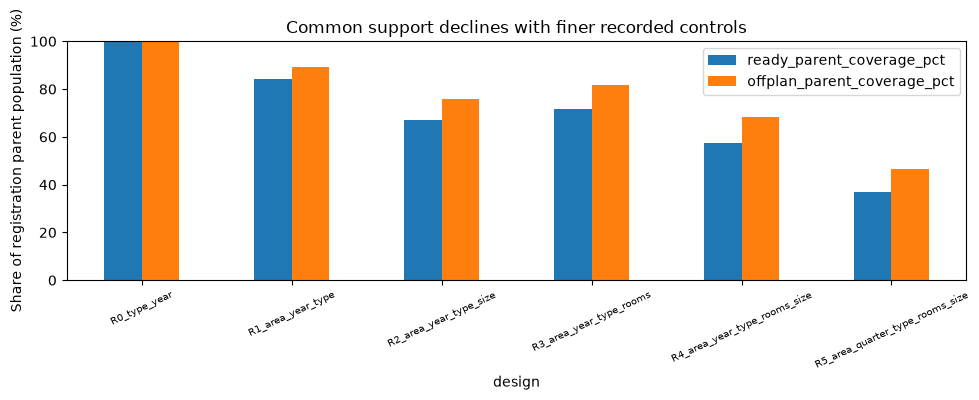

In [14]:
# Preserve the exact two-sided matched population without dtype-dependent fillna.
if SELECTED_REG:
    keys=REG_DESIGNS[SELECTED_REG]
    reg_matched=DESIGN_FRAMES[SELECTED_REG].merge(registration_matched_cells[keys],on=keys,how='inner',validate='many_to_one')
    assert reg_matched.transaction_id.is_unique
    observed=reg_matched.groupby('reg_type_label').size().reindex(['Ready','Off-Plan'],fill_value=0)
    assert observed.eq(registration_matched_cells[['Ready','Off-Plan']].sum()).all()
    matched_ids=set(reg_matched.transaction_id)
else:
    reg_matched=REG_WINDOW.iloc[:0].copy()
    matched_ids=set()
reg_unmatched=REG_WINDOW[['transaction_id','reg_type_label']].copy()
reg_unmatched['in_match']=reg_unmatched.transaction_id.isin(matched_ids).astype(bool)
assert reg_unmatched.in_match.sum()==len(reg_matched)
registration_unmatched_audit=(reg_unmatched.groupby(['reg_type_label','in_match'],observed=True).size().rename('n').reset_index())
registration_matching_coverage=pd.DataFrame([dict(reg_type_label=side,parent_n=int(PARENT_REG[side]),matched_n=int((reg_matched.reg_type_label==side).sum()),coverage_pct=ratio_coverage(int((reg_matched.reg_type_label==side).sum()),int(PARENT_REG[side]))) for side in ['Ready','Off-Plan']])
assert int(registration_matching_coverage.matched_n.sum())==len(reg_matched)
display(registration_matching_coverage,registration_unmatched_audit)
fig,ax=plt.subplots(figsize=(10,4));v=registration_overlap_feasibility.query('min_cell_n==30').set_index('design')
v[['ready_parent_coverage_pct','offplan_parent_coverage_pct']].plot.bar(ax=ax)
ax.set(ylabel='Share of registration parent population (%)',title='Common support declines with finer recorded controls',ylim=(0,100))
ax.tick_params(axis='x',rotation=25,labelsize=7)
fig.tight_layout();fig.savefig(FIG/'05_matching_support.png',dpi=140);plt.show()


In [15]:
# Explicit Year × Property Type × Registration match and feature selection.
# Separate characteristic-known loss from loss due to two-sided common support.
sel_rows=[]
for (yr,typ,side),parent in REG_WINDOW.groupby(['year','property_type_label','reg_type_label'],observed=True):
    feature=DESIGN_FRAMES[SELECTED_REG] if SELECTED_REG else REG_WINDOW.iloc[:0]
    feature_rows=feature.loc[feature.year.eq(yr)&feature.property_type_label.eq(typ)&feature.reg_type_label.eq(side)]
    m=reg_matched.loc[reg_matched.year.eq(yr)&reg_matched.property_type_label.eq(typ)&reg_matched.reg_type_label.eq(side)]
    sel_rows.append(dict(year=int(yr),property_type_label=typ,reg_type_label=side,
      parent_n=len(parent),feature_n=len(feature_rows),matched_n=len(m),missing_feature_n=len(parent)-len(feature_rows),
      unmatched_after_feature_n=len(feature_rows)-len(m),feature_pct=ratio_coverage(len(feature_rows),len(parent)),
      match_parent_pct=ratio_coverage(len(m),len(parent)),match_feature_pct=ratio_coverage(len(m),len(feature_rows))))
registration_segment_selection=pd.DataFrame(sel_rows)
assert ((registration_segment_selection.missing_feature_n+registration_segment_selection.unmatched_after_feature_n+registration_segment_selection.matched_n)==registration_segment_selection.parent_n).all()
display(registration_segment_selection.query('year==2025'))

,year,property_type_label,reg_type_label,parent_n,feature_n,matched_n,missing_feature_n,unmatched_after_feature_n,feature_pct,match_parent_pct,match_feature_pct
20,2025,Unit,Off-Plan,119449,119444,85987,5,33457,99.995814,71.986371,71.989384
21,2025,Unit,Ready,43873,43822,32396,51,11426,99.883755,73.840403,73.926338
22,2025,Villa,Off-Plan,9113,9112,4886,1,4226,99.989027,53.615714,53.621598
23,2025,Villa,Ready,6527,4633,1758,1894,2875,70.982074,26.934273,37.945176


In [16]:
# New estimator is independent from Notebook 02 year-over-year functions.
def contemporaneous_gap(frame,keys,min_n=30,weight_mode='pooled'):
 required=set(keys)|{'reg_type_label','log_psm','transaction_id'}
 if not required.issubset(frame.columns):raise ValueError(f'Missing {required-set(frame.columns)}')
 if frame.transaction_id.duplicated().any():raise ValueError('Duplicate transaction IDs')
 z=frame.loc[frame.reg_type_label.isin(['Ready','Off-Plan'])].dropna(subset=list(keys)+['log_psm']).copy()
 if not np.isfinite(z.log_psm.to_numpy(dtype=float)).all():raise ValueError('Nonfinite log price')
 gp=z.groupby(list(keys)+['reg_type_label'],observed=True).agg(n=('transaction_id','size'),mean_log=('log_psm','mean'),median_log=('log_psm','median')).reset_index()
 wide=gp.pivot(index=list(keys),columns='reg_type_label',values=['n','mean_log','median_log'])
 if wide.empty or 'Ready' not in wide['n'] or 'Off-Plan' not in wide['n']:
  return None,pd.DataFrame()
 keep=wide['n']['Ready'].ge(min_n)&wide['n']['Off-Plan'].ge(min_n)
 tab=wide.loc[keep].copy()
 if tab.empty:return None,pd.DataFrame()
 nready=tab[('n','Ready')].astype(float);noff=tab[('n','Off-Plan')].astype(float)
 if weight_mode=='pooled':ww=nready+noff
 elif weight_mode=='ready':ww=nready
 elif weight_mode=='offplan':ww=noff
 elif weight_mode=='equal':ww=pd.Series(1.,index=tab.index)
 else:raise ValueError('Unknown weight_mode')
 ww=ww/ww.sum()
 delta=tab[('mean_log','Off-Plan')]-tab[('mean_log','Ready')]
 med=tab[('median_log','Off-Plan')]-tab[('median_log','Ready')]
 det=pd.DataFrame(dict(ready_n=nready,offplan_n=noff,weight=ww,mean_log_gap=delta,median_log_gap=med,contribution=ww*delta)).reset_index()
 out=dict(strata=len(det),ready_n=int(nready.sum()),offplan_n=int(noff.sum()),effective_strata=float(1/(ww*ww).sum()),largest_weight_pct=float(100*ww.max()),log_gap=float(np.dot(ww,delta)),gap_pct=float(100*np.expm1(np.dot(ww,delta))),median_log_gap=float(np.dot(ww,med)),median_gap_pct=float(100*np.expm1(np.dot(ww,med))),weight_mode=weight_mode)
 assert np.isclose(det.weight.sum(),1) and np.isclose(det.contribution.sum(),out['log_gap'])
 return out,det
if SELECTED_REG:
 reg_primary,reg_detail=contemporaneous_gap(DESIGN_FRAMES[SELECTED_REG],REG_DESIGNS[SELECTED_REG],PRIMARY_MIN_N)
 reg_primary.update(design=SELECTED_REG,decision='QUALIFIED',target='P1 Strict overlapping registration strata, 2020–2025')
 offplan_ready_matched_gap=pd.DataFrame([reg_primary]);offplan_ready_stratum_detail=reg_detail
else:
 offplan_ready_matched_gap=pd.DataFrame(columns=['design','log_gap','gap_pct','ready_n','offplan_n','decision']);offplan_ready_stratum_detail=pd.DataFrame()
display(offplan_ready_matched_gap,offplan_ready_stratum_detail.head())

,strata,ready_n,offplan_n,effective_strata,largest_weight_pct,log_gap,gap_pct,median_log_gap,median_gap_pct,weight_mode,design,decision,target
0,693,122095,253849,275.879845,1.810908,0.296148,34.466852,0.305525,35.733808,pooled,R4_area_year_type_rooms_size,QUALIFIED,"P1 Strict overlapping registration strata, 202..."


,area_key,year,property_type_label,rooms_bucket,size_coarse,ready_n,offplan_n,weight,mean_log_gap,median_log_gap,contribution
0,232.0,2025,Unit,2.0,Unit:04,50.0,36.0,0.000229,0.309278,0.223479,0.000071
1,317.0,2022,Unit,1.0,Unit:02,82.0,171.0,0.000673,0.033983,0.073523,0.000023
2,317.0,2022,Unit,2.0,Unit:03,58.0,149.0,0.000551,-0.020632,-0.014804,-0.000011
3,317.0,2023,Unit,1.0,Unit:02,74.0,30.0,0.000277,-0.045851,-0.047966,-0.000013
4,330.0,2020,Unit,1.0,Unit:02,330.0,308.0,0.001697,0.594296,0.628357,0.001009


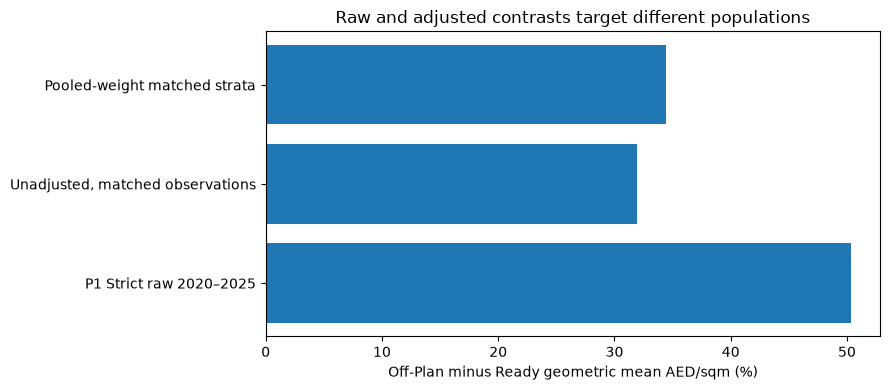

,method,population_n,log_gap,gap_pct
0,P1 Strict raw 2020–2025,584059,0.407633,50.325519
1,"Unadjusted, matched observations",375944,0.276859,31.897972
2,Pooled-weight matched strata,375944,0.296148,34.466852


In [17]:
# Raw gap and within-overlap raw gap target separate populations.
def simple_gap(v):
 a=v.loc[v.reg_type_label.eq('Ready'),'log_psm'];b=v.loc[v.reg_type_label.eq('Off-Plan'),'log_psm']
 return float(b.mean()-a.mean()) if len(a) and len(b) else np.nan
comp=[dict(method='P1 Strict raw 2020–2025',population_n=len(REG_WINDOW),log_gap=simple_gap(REG_WINDOW))]
if SELECTED_REG:
 comp.extend([dict(method='Unadjusted, matched observations',population_n=len(reg_matched),log_gap=simple_gap(reg_matched)),dict(method='Pooled-weight matched strata',population_n=len(reg_matched),log_gap=reg_primary['log_gap'])])
raw_matched_gap_comparison=pd.DataFrame(comp);raw_matched_gap_comparison['gap_pct']=100*np.expm1(raw_matched_gap_comparison.log_gap)
fig,ax=plt.subplots(figsize=(9,4));ax.barh(raw_matched_gap_comparison.method,raw_matched_gap_comparison.gap_pct);ax.axvline(0,c='gray');ax.set(xlabel='Off-Plan minus Ready geometric mean AED/sqm (%)',title='Raw and adjusted contrasts target different populations');fig.tight_layout();fig.savefig(FIG/'05_raw_vs_matched_gap.png',dpi=140);plt.show()
display(raw_matched_gap_comparison)

### Fixed-effects identification and dependence
A cell fixed-effect OLS coefficient is not automatically the same as a pooled-weight matched contrast: the within-cell OLS estimand weights by `n_ready*n_off/(n_ready+n_off)`. Community-clustered intervals are reported only when the number of identifying community clusters reaches the predeclared minimum. Project-label robustness remains conditional on metadata completeness.

In [18]:
def fe_registration_estimator(frame,keys,min_clusters=MIN_CLUSTER_COMMUNITIES):
    if frame.empty:return None
    group=frame.groupby(list(keys),observed=True).ngroup()
    x=frame.reg_type_label.eq('Off-Plan').to_numpy(dtype=float)
    y=frame.log_psm.to_numpy(dtype=float)
    temp=pd.DataFrame({'g':group,'x':x,'y':y,'area':frame.area_key.to_numpy()})
    means=temp.groupby('g')[['x','y']].transform('mean')
    xx=(temp.x-means.x).to_numpy();yy=(temp.y-means.y).to_numpy()
    denom=float(xx@xx)
    if denom<=1e-10:return None
    beta=float((xx@yy)/denom);residual=yy-beta*xx
    groups=int(temp.g.nunique());n=len(temp);rank=groups+1
    se_hc=float(np.sqrt(float(((xx*residual)**2).sum())/denom**2))
    scores=pd.DataFrame({'area':temp.area,'score':xx*residual}).groupby('area',dropna=False).score.sum()
    clusters=len(scores);se=np.nan;lo=np.nan;hi=np.nan
    if clusters>=min_clusters and n>rank and groups>0:
        # CR1 with absorbed cell fixed effects included in residual degrees of freedom.
        adjustment=clusters/(clusters-1)*(n-1)/(n-rank)
        se=float(np.sqrt(adjustment*float((scores*scores).sum())/denom**2))
        critical=float(stats.t.ppf(.975,clusters-1))
        lo=beta-critical*se;hi=beta+critical*se
    return dict(beta=beta,gap_pct=100*np.expm1(beta),se_hc0=se_hc,se_cluster=se,
       ci_low_pct=100*np.expm1(lo) if np.isfinite(lo) else np.nan,
       ci_high_pct=100*np.expm1(hi) if np.isfinite(hi) else np.nan,
       clusters=clusters,n=n,absorbed_cells=groups,model_rank=rank,cluster_df=clusters-1,
       identified=denom>0,covariance='community CR1, absorbed-FE df' if np.isfinite(se) else 'CLUSTER INFERENCE WITHHELD')
fe=fe_registration_estimator(reg_matched,REG_DESIGNS[SELECTED_REG]) if SELECTED_REG else None
registration_regression=pd.DataFrame([fe]) if fe else pd.DataFrame(columns=['beta','gap_pct','se_cluster','clusters','n','identified'])
display(registration_regression)


,beta,gap_pct,se_hc0,se_cluster,ci_low_pct,ci_high_pct,clusters,n,absorbed_cells,model_rank,cluster_df,identified,covariance
0,0.297238,34.613629,0.00103,0.04621,22.627718,47.771069,43,375944,693,694,42,True,"community CR1, absorbed-FE df"


In [19]:
registration_model_diagnostics=pd.DataFrame([dict(design=SELECTED_REG or 'NONE',n=len(reg_matched),
    communities=int(reg_matched.area_key.nunique()) if len(reg_matched) else 0,
    project_name_known_pct=float(100*reg_matched.project_name.notna().mean()) if len(reg_matched) else np.nan,
    largest_community_pct=float(100*reg_matched.area_key.value_counts(normalize=True).max()) if len(reg_matched) else np.nan,
    regression_identified=bool(fe and fe['identified']),
    cluster_inference_feasible=bool(fe and np.isfinite(fe['se_cluster'])),
    absorbed_cells=fe['absorbed_cells'] if fe else np.nan,
    interpretation='Within supported stratum association; community-cluster dependence')])
# The cell-FE estimator is a weighted average of stratum contrasts with weight n_R*n_O/(n_R+n_O).
if SELECTED_REG and fe:
    stratum_weights=reg_detail.ready_n*reg_detail.offplan_n/(reg_detail.ready_n+reg_detail.offplan_n)
    independent_beta=np.average(reg_detail.mean_log_gap,weights=stratum_weights)
    assert np.isclose(independent_beta,fe['beta'],atol=1e-9),'FE coefficient does not reconcile to weighted stratum contrast'
    registration_model_diagnostics['fe_identity_error']=abs(independent_beta-fe['beta'])
display(registration_model_diagnostics)


,design,n,communities,project_name_known_pct,largest_community_pct,regression_identified,cluster_inference_feasible,absorbed_cells,interpretation,fe_identity_error
0,R4_area_year_type_rooms_size,375944,43,93.916647,14.501096,True,True,693,Within supported stratum association; communit...,1.054712e-15


In [20]:
hetero=[]
for typ in ['Unit','Villa']:
 if not SELECTED_REG:continue
 z=REG_WINDOW.loc[REG_WINDOW.property_type_label.eq(typ)]
 estimate,detail=contemporaneous_gap(z,REG_DESIGNS[SELECTED_REG],PRIMARY_MIN_N)
 if estimate:
  hetero.append(dict(segment=typ,design=SELECTED_REG,**estimate))
registration_gap_heterogeneity=pd.DataFrame(hetero) if hetero else pd.DataFrame(columns=['segment','gap_pct','ready_n','offplan_n'])
display(registration_gap_heterogeneity)

,segment,design,strata,ready_n,offplan_n,effective_strata,largest_weight_pct,log_gap,gap_pct,median_log_gap,median_gap_pct,weight_mode
0,Unit,R4_area_year_type_rooms_size,627,115768,237337,249.783653,1.928038,0.312120,36.631918,0.322913,38.114500,pooled
1,Villa,R4_area_year_type_rooms_size,66,6327,16512,39.703722,5.092167,0.049197,5.042755,0.036706,3.738787,pooled


In [21]:
# Preliminary result; the publication decision is finalized after clustered uncertainty,
# temporal support, missingness and robustness are known (final acceptance cell).
r11_status='NOT ESTIMABLE' if not SELECTED_REG else 'QUALIFIED'
r11_reason='No prespecified two-sided common support' if not SELECTED_REG else 'PROVISIONAL: fixed-stratum observational gap; final dependence/selection gate pending'
rq11_decision=pd.DataFrame([dict(rq='RQ11',decision=r11_status,design=SELECTED_REG or 'NONE',
   estimate_pct=float(offplan_ready_matched_gap.gap_pct.iloc[0]) if SELECTED_REG else np.nan,
   ready_coverage_pct=float(registration_matching_coverage.loc[0,'coverage_pct']),
   offplan_coverage_pct=float(registration_matching_coverage.loc[1,'coverage_pct']),restriction=r11_reason)])
display(rq11_decision)


,rq,decision,design,estimate_pct,ready_coverage_pct,offplan_coverage_pct,restriction
0,RQ11,QUALIFIED,R4_area_year_type_rooms_size,34.466852,57.491101,68.296443,PROVISIONAL: fixed-stratum observational gap; ...


## 05. RQ10 — Nonlinear size–price associations
Use `log(price AED)` as primary outcome. For identical OLS sample and regressors, the `log(AED/sqm)` area coefficient must equal total-price elasticity **minus one**; this is a mathematical identity, not independent evidence. Separate Unit and Villa support, avoid extrapolation and keep models descriptive.

In [22]:
size_support=(r.groupby(['year','property_type_label','reg_type_label'],observed=True,dropna=False).agg(n=('transaction_id','size'),min_area=('area_sqm','min'),p01_area=('area_sqm',lambda x:x.quantile(.01)),p10_area=('area_sqm',lambda x:x.quantile(.1)),p50_area=('area_sqm','median'),p90_area=('area_sqm',lambda x:x.quantile(.9)),p99_area=('area_sqm',lambda x:x.quantile(.99)),max_area=('area_sqm','max')).reset_index())
display(size_support.query('year==2025'))

,year,property_type_label,reg_type_label,n,min_area,p01_area,p10_area,p50_area,p90_area,p99_area,max_area
40,2025,Unit,Off-Plan,119449,7.09,31.8000,37.16,72.27,132.390,247.3000,4962.65
41,2025,Unit,Ready,43873,6.00,28.7832,38.97,77.35,155.218,310.2096,2736.91
42,2025,Villa,Off-Plan,9113,16.98,78.6000,96.19,187.31,350.730,549.3600,5395.97
43,2025,Villa,Ready,6527,5.23,52.8800,140.42,244.78,736.298,1522.8810,86607.43


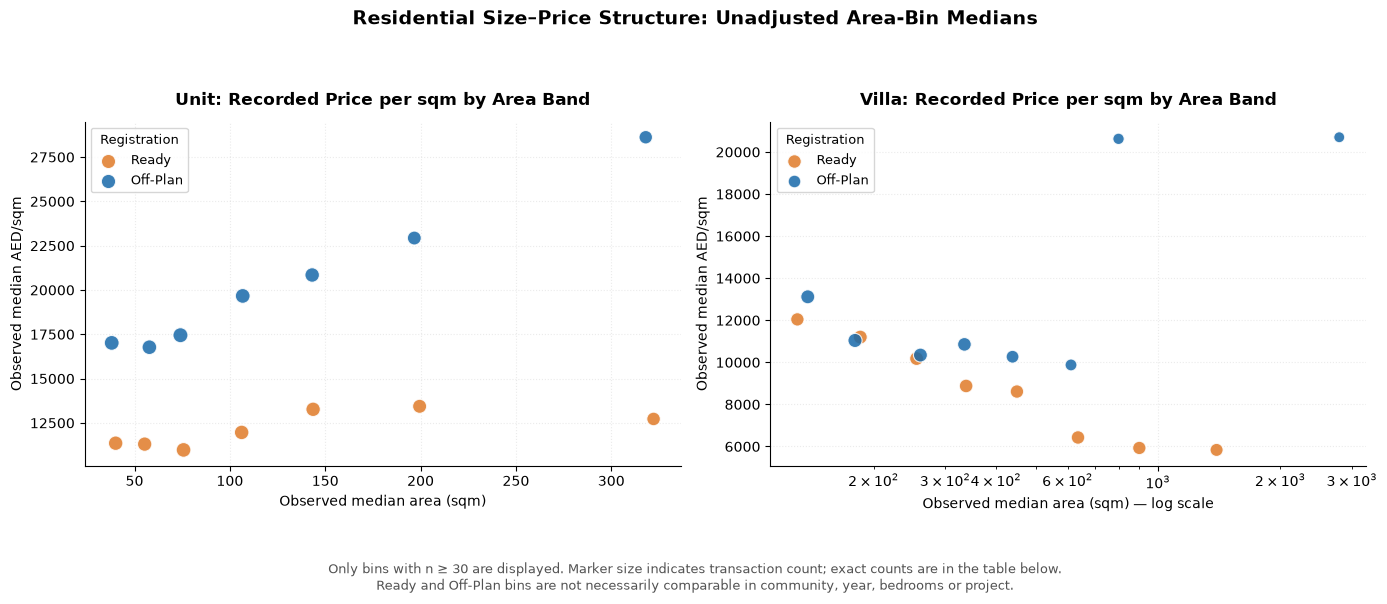

,property_type_label,size_coarse,reg_type_label,n,median_area,median_price,median_psm,mean_log_price
0,Unit,Unit:00,Off-Plan,83179,38.030,630099.0,17015.484515,13.369104
1,Unit,Unit:00,Ready,38376,40.100,436499.0,11354.126864,12.995048
2,Unit,Unit:01,Off-Plan,59491,57.790,949900.0,16770.611354,13.739968
3,Unit,Unit:01,Ready,30820,55.310,625000.0,11302.159091,13.386870
4,Unit,Unit:02,Off-Plan,121186,74.080,1300000.0,17448.252632,14.103212
5,Unit,Unit:02,Ready,64923,75.700,840000.0,10975.609756,13.655651
6,Unit,Unit:03,Off-Plan,73555,106.730,2065950.0,19665.241005,14.497066
7,Unit,Unit:03,Ready,44257,106.170,1275000.0,11962.827373,14.083352
8,Unit,Unit:04,Off-Plan,41358,143.150,3011826.0,20846.224567,14.859997
9,Unit,Unit:04,Ready,36503,143.640,1900000.0,13266.761769,14.475357


In [23]:

# RQ10 — Descriptive size-price associations
# Fixed physical area bands; no interpolation between bins.
# These are UNADJUSTED medians, not hedonic effects.

size_price_binned = (
    r.groupby(
        [
            "property_type_label",
            "size_coarse",
            "reg_type_label"
        ],
        observed=True
    )
    .agg(
        n=("transaction_id", "size"),
        median_area=("area_sqm", "median"),
        median_price=("price_aed", "median"),
        median_psm=("price_per_sqm", "median"),
        mean_log_price=("log_price", "mean")
    )
    .reset_index()
)

# ----------------------------
# Visualization settings
# ----------------------------

colors = {
    "Ready": "#E07A28",
    "Off-Plan": "#1769AA"
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5)
)

for ax, typ in zip(axes, ["Unit", "Villa"]):

    subset = size_price_binned.loc[
        (size_price_binned["property_type_label"] == typ)
        & (size_price_binned["n"] >= 30)
        & np.isfinite(size_price_binned["median_area"])
        & np.isfinite(size_price_binned["median_psm"])
        & (size_price_binned["median_area"] > 0)
    ].copy()

    if subset.empty:
        ax.text(
            0.5, 0.5,
            "No area bins meet the support threshold",
            transform=ax.transAxes,
            ha="center",
            va="center"
        )

    else:
        for reg in ["Ready", "Off-Plan"]:

            group = subset.loc[
                subset.reg_type_label.eq(reg)
            ].sort_values("median_area")

            if group.empty:
                continue

            # Marker area increases moderately with
            # bin count. This encodes relative support,
            # not statistical precision.
            marker_sizes = (
                35 + 16 * np.log10(group["n"].to_numpy())
            )

            ax.scatter(
                group["median_area"],
                group["median_psm"],
                s=marker_sizes,
                c=colors[reg],
                label=reg,
                alpha=0.85,
                edgecolors="white",
                linewidths=0.8,
                zorder=3
            )

        # Villas have a much wider size range.
        # Logarithmic x scaling makes the central
        # range readable without discarding large villas.
        if typ == "Villa":
            ax.set_xscale("log")

        ax.legend(
            title="Registration",
            loc="best",
            fontsize=9,
            title_fontsize=9,
            frameon=True
        )

    ax.set_title(
        f"{typ}: Recorded Price per sqm by Area Band",
        fontsize=12,
        weight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Observed median area (sqm)"
        + (" — log scale" if typ == "Villa" else "")
    )

    ax.set_ylabel("Observed median AED/sqm")

    ax.grid(
        axis="both",
        alpha=0.25,
        linestyle=":"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Residential Size–Price Structure: "
    "Unadjusted Area-Bin Medians",
    fontsize=14,
    weight="bold",
    y=1.02
)

fig.text(
    0.5, -0.035,
    "Only bins with n ≥ 30 are displayed. "
    "Marker size indicates transaction count; "
    "exact counts are in the table below.\n"
    "Ready and Off-Plan bins are not necessarily "
    "comparable in community, year, bedrooms or project.",
    ha="center",
    fontsize=9,
    color="#525252"
)

fig.tight_layout(rect=[0, 0.08, 1, 0.96])

fig.savefig(
    FIG / "05_size_price_binned.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Keep the complete original research table.
display(size_price_binned)


In [24]:
# Avoid enormous dense OLS matrices: within-community/year/registration FE demeaning.
def within_size_fit(x,yfield='log_price',group_keys=('area_key','year','reg_type_label')):
 x=x.dropna(subset=list(group_keys)+['log_area',yfield]).copy()
 if x.empty:return None
 groups=x.groupby(list(group_keys),observed=True,sort=False)
 xw=x.log_area-groups.log_area.transform('mean');yw=x[yfield]-groups[yfield].transform('mean')
 denom=float(xw@xw)
 if denom<=1e-10:return None
 beta=float((xw@yw)/denom);err=yw-beta*xw
 # HC0 and one-way community cluster for FE residualized slope, conditional on group specification.
 hc=float(np.sqrt(float(((xw*err)**2).sum())/denom**2))
 scores=pd.DataFrame({'area':x.area_key.to_numpy(),'s':(xw*err).to_numpy()}).groupby('area',dropna=False).s.sum()
 m=len(scores);cluster_se=np.nan
 if m>=MIN_CLUSTER_COMMUNITIES:cluster_se=float(np.sqrt((m/(m-1))*float((scores*scores).sum())/denom**2))
 return dict(beta=beta,se_hc0=hc,se_cluster=cluster_se,n=len(x),communities=m,within_ss=denom,group_count=groups.ngroups,rmse=float(np.sqrt(np.mean(err**2))),outcome=yfield)
SIZE_FRAMES={t:r.loc[r.property_type_label.eq(t) & r.area_key.notna() & r.reg_type_label.isin(['Ready','Off-Plan'])] for t in ['Unit','Villa']}
lin=[]
for typ,x in SIZE_FRAMES.items():
 for outcome in ['log_price','log_psm']:
  z=within_size_fit(x,outcome)
  if z:lin.append(dict(property_type_label=typ,**z))
size_price_linear_models=pd.DataFrame(lin)
assert len(size_price_linear_models)>0
for typ in size_price_linear_models.property_type_label.unique():
 p=size_price_linear_models.query('property_type_label==@typ').set_index('outcome').beta
 assert np.isclose(p['log_psm'],p['log_price']-1,atol=1e-9)
display(size_price_linear_models)

,property_type_label,beta,se_hc0,se_cluster,n,communities,within_ss,group_count,rmse,outcome
0,Unit,0.902042,0.000817,0.020049,632593,70,125957.599150,1049,0.222716,log_price
1,Unit,-0.097958,0.000817,0.020049,632593,70,125957.599150,1049,0.222716,log_psm
2,Villa,0.697731,0.003042,0.035996,104551,101,16619.186095,983,0.214980,log_price
3,Villa,-0.302269,0.003042,0.035996,104551,101,16619.186095,983,0.214980,log_psm


In [25]:
# ONE-KNOT PIECEWISE LINEAR LOG-AREA MODEL, not a cubic spline.
# Same fixed-effects transformation as the linear fit, with a community-cluster CR1 covariance.
def within_piecewise(frame,knot):
    z=frame.dropna(subset=['area_key','year','reg_type_label','log_area','log_price']).copy()
    z['hinge']=np.maximum(0,z.log_area-knot)
    fixed=['area_key','year','reg_type_label'];g=z.groupby(fixed,observed=True)
    XX=np.column_stack([(z.log_area-g.log_area.transform('mean')).to_numpy(dtype=float),
                        (z.hinge-g.hinge.transform('mean')).to_numpy(dtype=float)])
    yy=(z.log_price-g.log_price.transform('mean')).to_numpy(dtype=float)
    if np.linalg.matrix_rank(XX)<2:return None
    coefficients=np.linalg.lstsq(XX,yy,rcond=None)[0]
    resid=yy-XX@coefficients;n=len(z);nfe=g.ngroups;k=XX.shape[1]
    clusters=z.area_key.astype(str)
    score_df=pd.DataFrame(XX*resid[:,None],columns=['score_low','score_hinge'])
    score_df['community']=clusters.to_numpy()
    cluster_scores=score_df.groupby('community')[['score_low','score_hinge']].sum().to_numpy()
    G=len(cluster_scores)
    covariance=np.full((k,k),np.nan)
    if G>=MIN_CLUSTER_COMMUNITIES and n>nfe+k:
        inv=np.linalg.inv(XX.T@XX)
        covariance=(G/(G-1))*((n-1)/(n-nfe-k))*inv@cluster_scores.T@cluster_scores@inv
    slo=float(coefficients[0]);shi=float(coefficients.sum());hinge=float(coefficients[1])
    selo=float(np.sqrt(max(covariance[0,0],0))) if np.isfinite(covariance).all() else np.nan
    sehi=float(np.sqrt(max(covariance.sum(),0))) if np.isfinite(covariance).all() else np.nan
    seh=float(np.sqrt(max(covariance[1,1],0))) if np.isfinite(covariance).all() else np.nan
    threshold=float(stats.t.ppf(.975,G-1)) if G>=MIN_CLUSTER_COMMUNITIES else np.nan
    return dict(beta_low=slo,beta_high=shi,beta_hinge=hinge,se_low=selo,se_high=sehi,se_hinge=seh,
       hinge_t=hinge/seh if np.isfinite(seh) and seh>0 else np.nan,
       hinge_ci_low=hinge-threshold*seh if np.isfinite(seh) else np.nan,
       hinge_ci_high=hinge+threshold*seh if np.isfinite(seh) else np.nan,
       rmse=float(np.sqrt(np.mean(resid**2))),n=n,communities=G,absorbed_cells=nfe,
       knot_log_area=float(knot),knot_area_sqm=float(np.exp(knot)),
       lower_supported_sqm=float(z.area_sqm.quantile(.01)),upper_supported_sqm=float(z.area_sqm.quantile(.99)),
       inference='community CR1, conditional on observed knot and support' if np.isfinite(seh) else 'WITHHELD')
nonlin=[]
for typ,frame in SIZE_FRAMES.items():
    if len(frame)<500:continue
    knot=float(frame.log_area.median())
    z=within_piecewise(frame,knot)
    if z:nonlin.append(dict(property_type_label=typ,**z))
size_price_nonlinear_models=pd.DataFrame(nonlin)
display(size_price_nonlinear_models)


,property_type_label,beta_low,beta_high,beta_hinge,se_low,se_high,se_hinge,hinge_t,hinge_ci_low,hinge_ci_high,rmse,n,communities,absorbed_cells,knot_log_area,knot_area_sqm,lower_supported_sqm,upper_supported_sqm,inference
0,Unit,0.793014,0.985844,0.192830,0.033122,0.014702,0.036448,5.290523,0.120118,0.265543,0.220794,632593,70,1049,4.326250,75.66,30.36,305.8124,"community CR1, conditional on observed knot an..."
1,Villa,0.734426,0.678322,-0.056104,0.079851,0.044195,0.097506,-0.575388,-0.249553,0.137345,0.214854,104551,101,983,5.440641,230.59,78.08,1393.5500,"community CR1, conditional on observed knot an..."


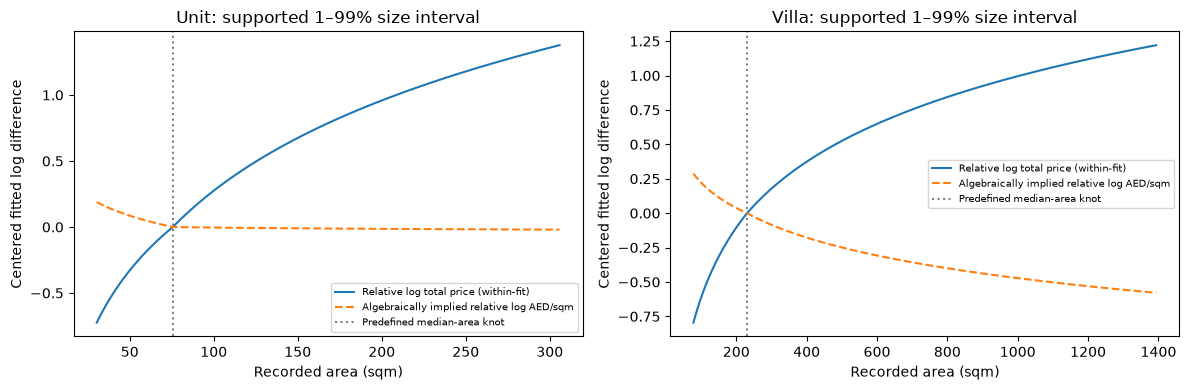

In [26]:
# Algebraically linked piecewise price/area curves; group demeaned fitted slopes
# describe observational predictions only, not same-property enlargement.
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=False)
for ax,typ in zip(axes,['Unit','Villa']):
    row=size_price_nonlinear_models.loc[size_price_nonlinear_models.property_type_label.eq(typ)]
    if not row.empty:
        z=row.iloc[0]
        support=np.linspace(np.log(z.lower_supported_sqm),np.log(z.upper_supported_sqm),100)
        xx=support-z.knot_log_area
        fit=z.beta_low*xx+z.beta_hinge*np.maximum(0,xx)
        ax.plot(np.exp(support),fit,label='Relative log total price (within-fit)')
        ax.plot(np.exp(support),fit-xx,label='Algebraically implied relative log AED/sqm',ls='--')
        ax.axvline(z.knot_area_sqm,ls=':',color='gray',label='Predefined median-area knot')
    ax.set(xlabel='Recorded area (sqm)',ylabel='Centered fitted log difference',title=f'{typ}: supported 1–99% size interval')
    ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(FIG/'05_size_piecewise_supported.png',dpi=140);plt.show()

In [27]:
size_denominator_identity=[]
for typ in ['Unit','Villa']:
 x=size_price_linear_models.query('property_type_label==@typ').set_index('outcome')
 if {'log_price','log_psm'}.issubset(x.index):
  residual=float(x.loc['log_psm','beta']-(x.loc['log_price','beta']-1))
  size_denominator_identity.append(dict(property_type_label=typ,identity_residual=residual,passed=abs(residual)<1e-9))
size_denominator_identity=pd.DataFrame(size_denominator_identity)
assert size_denominator_identity.passed.all()
display(size_denominator_identity)

,property_type_label,identity_residual,passed
0,Unit,-9.020562e-16,True
1,Villa,-5.551115e-17,True


In [28]:
# Registration-group size interactions: estimate within community/year where estimable.
size_interactions=[]
for typ,frame in SIZE_FRAMES.items():
 for reg in ['Ready','Off-Plan']:
  sub=frame.loc[frame.reg_type_label.eq(reg)]
  z=within_size_fit(sub,group_keys=('area_key','year'))
  if z:size_interactions.append(dict(property_type_label=typ,reg_type_label=reg,**z))
size_interactions=pd.DataFrame(size_interactions)
display(size_interactions)

,property_type_label,reg_type_label,beta,se_hc0,se_cluster,n,communities,within_ss,group_count,rmse,outcome
0,Unit,Ready,0.882866,0.001460,0.017252,236872,66,52745.666353,566,0.273116,log_price
1,Unit,Off-Plan,0.915858,0.000935,0.025483,395721,62,73211.932797,483,0.185902,log_price
2,Villa,Ready,0.726264,0.003932,0.039186,49892,98,11657.858850,824,0.257620,log_price
3,Villa,Off-Plan,0.630685,0.003666,0.047324,54659,27,4961.327245,159,0.165047,log_price


In [29]:
# Within community/year/registration fixed-effects interaction regression.
# This is a same-sample formal test of differential observational size slopes.
def size_registration_interaction(frame):
    z=frame.dropna(subset=['area_key','year','reg_type_label','log_area','log_price']).copy()
    if z.empty or z.reg_type_label.nunique()!=2:return None
    d=z.reg_type_label.eq('Off-Plan').to_numpy(dtype=float)
    z['_interaction']=z.log_area.to_numpy(dtype=float)*d
    groups=z.groupby(['area_key','year','reg_type_label'],observed=True)
    x1=z.log_area-groups.log_area.transform('mean')
    x2=z._interaction-groups._interaction.transform('mean')
    xx=np.column_stack([x1.to_numpy(dtype=float),x2.to_numpy(dtype=float)])
    yy=(z.log_price-groups.log_price.transform('mean')).to_numpy(dtype=float)
    if np.linalg.matrix_rank(xx)!=2:return None
    coeff=np.linalg.lstsq(xx,yy,rcond=None)[0];residual=yy-xx@coeff
    score=pd.DataFrame(xx*residual[:,None],columns=['base','interaction'])
    score['area']=z.area_key.to_numpy()
    cs=score.groupby('area')[['base','interaction']].sum().to_numpy()
    G=len(cs);ng=groups.ngroups;n=len(z);k=2
    if G<MIN_CLUSTER_COMMUNITIES or n<=ng+k:return None
    inv=np.linalg.inv(xx.T@xx)
    v=(G/(G-1))*((n-1)/(n-ng-k))*inv@(cs.T@cs)@inv
    se=np.sqrt(np.maximum(np.diag(v),0));critical=float(stats.t.ppf(.975,G-1))
    return dict(n=n,communities=G,absorbed_cells=ng,
      beta_ready=float(coeff[0]),beta_offplan=float(coeff.sum()),
      beta_difference=float(coeff[1]),se_difference=float(se[1]),
      difference_ci_low=float(coeff[1]-critical*se[1]),
      difference_ci_high=float(coeff[1]+critical*se[1]),
      restriction='Same-sample community/year/registration FE interaction; noncausal association')
size_interaction_joint=pd.DataFrame([dict(property_type_label=typ,**res)
    for typ,frame in SIZE_FRAMES.items() if (res:=size_registration_interaction(frame)) is not None])
display(size_interaction_joint)

,property_type_label,n,communities,absorbed_cells,beta_ready,beta_offplan,beta_difference,se_difference,difference_ci_low,difference_ci_high,restriction
0,Unit,632593,70,1049,0.882866,0.915858,0.032992,0.019778,-0.006465,0.072449,Same-sample community/year/registration FE int...
1,Villa,104551,101,983,0.726264,0.630685,-0.095578,0.047544,-0.189905,-0.001252,Same-sample community/year/registration FE int...


In [30]:
rq10_decision=pd.DataFrame([dict(rq='RQ10',decision='QUALIFIED' if not size_price_linear_models.empty and size_denominator_identity.passed.all() else 'BLOCKED',restriction='PROVISIONAL: observational within-community/year/registration elasticities; nonlinear inference and trimming sensitivity evaluated later')])
display(rq10_decision)


,rq,decision,restriction
0,RQ10,QUALIFIED,PROVISIONAL: observational within-community/ye...


## 06. RQ12 — Bedroom and parking attributes
Primary population: Ready residential Units in 2015–2025. Bedroom categories remain categorical (5 = **5+**); missing bedrooms/parking are never assigned a reference category. P3 is intersected with Ready Units and known geography explicitly. Any interpreted coefficient is an observational conditional association, not an amenity premium.

In [31]:
AMENITY_PARENT=r.loc[r.property_type_label.eq('Unit') & r.reg_type_label.eq('Ready')].copy()
AMENITY_KNOWN=AMENITY_PARENT.loc[AMENITY_PARENT.rooms_bucket.notna() & AMENITY_PARENT.has_parking.notna() & AMENITY_PARENT.area_key.notna()].copy()
assert AMENITY_KNOWN.transaction_id.isin(p3.transaction_id).all()
bed=[]
for (yr,room),g in AMENITY_PARENT.groupby(['year','rooms_bucket'],dropna=False,observed=True):
 bed.append(dict(year=yr,rooms_bucket=room,n=len(g),median_area=g.area_sqm.median(),median_price=g.price_aed.median(),median_psm=g.price_per_sqm.median()))
bedroom_support=pd.DataFrame(bed)
selection_amenity=pd.DataFrame([dict(parent_n=len(AMENITY_PARENT),known_bedroom_n=int(AMENITY_PARENT.rooms_bucket.notna().sum()),known_parking_n=int(AMENITY_PARENT.has_parking.notna().sum()),both_known_with_geography_n=len(AMENITY_KNOWN),retained_pct=ratio_coverage(len(AMENITY_KNOWN),len(AMENITY_PARENT)))])
display(selection_amenity,bedroom_support.query('year==2025').head(10))

,parent_n,known_bedroom_n,known_parking_n,both_known_with_geography_n,retained_pct
0,236872,236323,236872,236323,99.768229


,year,rooms_bucket,n,median_area,median_price,median_psm
70,2025,0.0,9975,40.900,550000.0,13899.920572
71,2025,1.0,18537,73.470,1000000.0,13913.483430
72,2025,2.0,11490,119.875,1835054.5,15268.745543
73,2025,3.0,3429,178.910,3500000.0,18701.496412
74,2025,4.0,324,312.790,7418219.5,20045.027769
75,2025,5.0,67,549.800,10400000.0,18109.938889
76,2025,NaN,51,234.860,5500000.0,19537.609899


,rooms_bucket,n,median_area,median_price,median_psm
0,0.0,50340,43.000,460000.0,10904.804008
1,1.0,96945,75.470,850000.0,11324.315823
2,2.0,64087,124.820,1600000.0,12687.239093
3,3.0,22000,186.520,2700000.0,13744.495582
4,4.0,2610,307.395,5000000.0,14369.806598
5,5.0,341,571.060,8500000.0,14884.600567


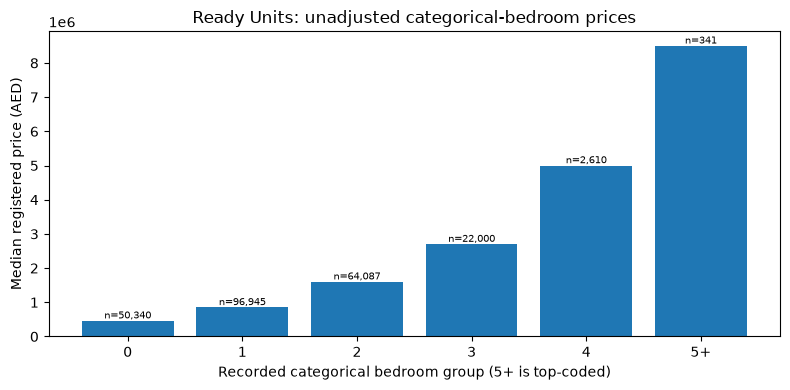

In [32]:
bedroom_descriptive=(AMENITY_PARENT.loc[AMENITY_PARENT.rooms_bucket.notna()].groupby('rooms_bucket',observed=True).agg(n=('transaction_id','size'),median_area=('area_sqm','median'),median_price=('price_aed','median'),median_psm=('price_per_sqm','median')).reset_index())
display(bedroom_descriptive)
fig,ax=plt.subplots(figsize=(8,4));z=bedroom_descriptive.loc[bedroom_descriptive.n>=30]
ax.bar(z.rooms_bucket.astype(int).astype(str).replace({'5':'5+'}),z.median_price)
for xpos,(_,row) in enumerate(z.iterrows()):ax.annotate(f'n={int(row.n):,}',(xpos,row.median_price),ha='center',va='bottom',fontsize=7)
ax.set(xlabel='Recorded categorical bedroom group (5+ is top-coded)',ylabel='Median registered price (AED)',title='Ready Units: unadjusted categorical-bedroom prices')
fig.tight_layout();fig.savefig(FIG/'05_bedroom_descriptive.png',dpi=140);plt.show()


In [33]:
# Reference encoding MUST be canonical (1 and 1.0 denote the same category).
# Design includes known recorded area and explicit community/year fixed effects.
def within_categorical_fit(frame,category,reference=1,min_group=30,min_clusters=15):
    required=['area_key','year','log_area','log_price',category]
    x=frame.dropna(subset=required).copy()
    values=pd.to_numeric(x[category],errors='coerce')
    if values.isna().any():raise ValueError('Non-numeric bedroom category in selected model')
    if not np.isfinite(x[['log_area','log_price']].to_numpy(dtype=float)).all():raise ValueError('Nonfinite modeling inputs')
    if (values%1).ne(0).any():raise ValueError('Noninteger bedroom category; do not coerce silently')
    x['_bed']=values.astype(int)
    counts=x['_bed'].value_counts();levels=sorted(int(v) for v in counts[counts>=min_group].index)
    if len(levels)<2:return pd.DataFrame(),dict(status='NOT ESTIMABLE',reason='insufficient categories')
    ref=int(reference)
    if ref not in levels:return pd.DataFrame(),dict(status='NOT ESTIMABLE',reason='preregistered reference missing')
    x=x.loc[x._bed.isin(levels)].copy()
    names=[f'bed_{v}' for v in levels if v!=ref]
    dummy=pd.DataFrame({f'bed_{v}':x._bed.eq(v).astype(float) for v in levels if v!=ref},index=x.index)
    assert f'bed_{ref}' not in dummy.columns and len(dummy.columns)==len(levels)-1
    fixed=['area_key','year'];group=x.groupby(fixed,observed=True,sort=False)
    XX=pd.concat([x[['log_area']],dummy],axis=1)
    # group index maps on the SAME x rows: avoid accidental alignment/reordering.
    Xw=XX-XX.groupby([x.area_key,x.year],observed=True).transform('mean')
    yw=x.log_price-group.log_price.transform('mean')
    cols=list(Xw.columns);Xmat=Xw.to_numpy(dtype=float);yvec=yw.to_numpy(dtype=float)
    rank=int(np.linalg.matrix_rank(Xmat));full_rank=(rank==len(cols))
    if not full_rank:return pd.DataFrame(),dict(status='NOT ESTIMABLE',reason='real rank deficiency after corrected coding',n=len(x),rank=rank,k=len(cols))
    G=int(x.area_key.nunique());ngroups=group.ngroups;n=len(x)
    if G<min_clusters or n<=ngroups+len(cols):
        return pd.DataFrame(),dict(status='NOT ESTIMABLE',reason='insufficient independent community support',n=n,communities=G)
    b=np.linalg.lstsq(Xmat,yvec,rcond=None)[0]
    resid=yvec-Xmat@b
    scores=pd.DataFrame(Xmat*resid[:,None],columns=cols)
    scores['area_key']=x.area_key.to_numpy()
    clustered=scores.groupby('area_key',observed=True)[cols].sum().to_numpy()
    bread=np.linalg.inv(Xmat.T@Xmat)
    adjustment=G/(G-1)*(n-1)/(n-ngroups-len(cols))
    vcov=adjustment*bread@(clustered.T@clustered)@bread
    diagonal=np.diag(vcov)
    if not np.isfinite(diagonal).all() or (diagonal<0).any():
        return pd.DataFrame(),dict(status='BLOCKED',reason='invalid clustered covariance')
    se=np.sqrt(diagonal);critical=float(stats.t.ppf(.975,G-1))
    table=pd.DataFrame(dict(term=cols,beta=b,se_cluster=se,ci_low=b-critical*se,ci_high=b+critical*se,
       n=n,communities=G,absorbed_cells=ngroups,reference=str(ref),category=category))
    table['association_pct']=100*np.expm1(table.beta)
    table['ci_low_pct']=100*np.expm1(table.ci_low)
    table['ci_high_pct']=100*np.expm1(table.ci_high)
    # An area coefficient is an elasticity, not an amenity percentage premium.
    table.loc[table.term.eq('log_area'),'association_pct']=np.nan
    table.loc[table.term.eq('log_area'),['ci_low_pct','ci_high_pct']]=np.nan
    return table,dict(status='QUALIFIED',reason='Full rank; community CR1 covariance conditional on observed cohort',
       n=n,communities=G,rank=rank,k=len(cols),reference=ref)
bedroom_adjusted,bedroom_meta=within_categorical_fit(AMENITY_PARENT,'rooms_bucket',reference=1)
display(bedroom_adjusted,bedroom_meta)


,term,beta,se_cluster,ci_low,ci_high,n,communities,absorbed_cells,reference,category,association_pct,ci_low_pct,ci_high_pct
0,log_area,0.772702,0.037174,0.698460,0.846944,236323,66,566,1,rooms_bucket,NaN,NaN,NaN
1,bed_0,0.000085,0.025753,-0.051348,0.051518,236323,66,566,1,rooms_bucket,0.008513,-5.005206,5.286851
2,bed_2,0.100454,0.022923,0.054674,0.146235,236323,66,566,1,rooms_bucket,10.567307,5.619610,15.746777
3,bed_3,0.201600,0.043059,0.115604,0.287595,236323,66,566,1,rooms_bucket,22.335802,12.255162,33.321694
4,bed_4,0.300716,0.071462,0.157996,0.443435,236323,66,566,1,rooms_bucket,35.082542,17.116195,55.805036
5,bed_5,0.548017,0.098971,0.350359,0.745676,236323,66,566,1,rooms_bucket,72.982015,41.957726,110.786537


{'status': 'QUALIFIED',
 'reason': 'Full rank; community CR1 covariance conditional on observed cohort',
 'n': 236323,
 'communities': 66,
 'rank': 6,
 'k': 6,
 'reference': 1}

In [34]:
# Check BOTH category co-occurrence and size-support overlap within the same community-year.
# This is an interpretation/publication gate, not a claim of comparable building quality.
bedroom_contrast_support=[]
if bedroom_meta.get('status')=='QUALIFIED':
    known=AMENITY_PARENT.dropna(subset=['area_key','year','rooms_bucket','log_area']).copy()
    known['_bed']=pd.to_numeric(known.rooms_bucket,errors='raise').astype(int)
    ref=int(bedroom_meta['reference'])
    cell_keys=['area_key','year']
    stats_by_cell=(known.groupby(cell_keys+['_bed'],observed=True)
        .agg(n=('transaction_id','size'),q10=('log_area',lambda a:a.quantile(.1)),
             q90=('log_area',lambda a:a.quantile(.9))).reset_index())
    ref_cells=stats_by_cell.loc[stats_by_cell._bed.eq(ref)].drop(columns='_bed').rename(
        columns={'n':'n_ref','q10':'lo_ref','q90':'hi_ref'})
    for term in bedroom_adjusted.term:
        if not term.startswith('bed_'):continue
        level=int(term.split('_')[1])
        alt=stats_by_cell.loc[stats_by_cell._bed.eq(level)].drop(columns='_bed').rename(
            columns={'n':'n_alt','q10':'lo_alt','q90':'hi_alt'})
        pair=ref_cells.merge(alt,on=cell_keys,how='inner',validate='one_to_one')
        pair=pair.loc[pair.n_ref.ge(5)&pair.n_alt.ge(5)].copy()
        if not pair.empty:
            pair['overlap_low']=pair[['lo_ref','lo_alt']].max(axis=1)
            pair['overlap_high']=pair[['hi_ref','hi_alt']].min(axis=1)
            pair['area_overlap']=pair.overlap_high.gt(pair.overlap_low)
            paired=int(pair.area_key.nunique())
            overlap=pair.loc[pair.area_overlap]
            overlap_communities=int(overlap.area_key.nunique())
            nref=int(pair.n_ref.sum());nalt=int(pair.n_alt.sum())
            overlap_nref=int(overlap.n_ref.sum());overlap_nalt=int(overlap.n_alt.sum())
        else:
            paired=overlap_communities=nref=nalt=overlap_nref=overlap_nalt=0
        category_supported=bool(paired>=10 and nref>=30 and nalt>=30)
        area_supported=bool(overlap_communities>=10 and overlap_nref>=30 and overlap_nalt>=30)
        supported=category_supported and area_supported
        bedroom_contrast_support.append(dict(term=term,reference=ref,category_level=level,
            paired_communities=paired,area_overlap_communities=overlap_communities,
            ref_n_in_pair_cells=nref,category_n_in_pair_cells=nalt,
            ref_n_in_area_overlap_cells=overlap_nref,category_n_in_area_overlap_cells=overlap_nalt,
            category_supported=category_supported,area_overlap_supported=area_supported,
            decision='QUALIFIED' if supported else 'INCONCLUSIVE',
            restriction='Community-year pair support and overlapping central 10–90% log-area ranges; residual confounding remains'))
bedroom_contrast_support=pd.DataFrame(bedroom_contrast_support)
if not bedroom_adjusted.empty:
    bedroom_adjusted=bedroom_adjusted.merge(
        bedroom_contrast_support[['term','paired_communities','area_overlap_communities',
                                  'area_overlap_supported','decision']],on='term',how='left',validate='one_to_one')
    bedroom_adjusted.loc[bedroom_adjusted.term.eq('log_area'),'decision']='SIZE_CONTROL'
    bedroom_adjusted.loc[bedroom_adjusted.decision.eq('INCONCLUSIVE'),
                         ['association_pct','ci_low_pct','ci_high_pct']]=np.nan
print('Bedroom categories without sufficient area overlap have their percentage contrasts withheld.')
display(bedroom_contrast_support,bedroom_adjusted)


Bedroom categories without sufficient area overlap have their percentage contrasts withheld.


,term,reference,category_level,paired_communities,area_overlap_communities,ref_n_in_pair_cells,category_n_in_pair_cells,ref_n_in_area_overlap_cells,category_n_in_area_overlap_cells,category_supported,area_overlap_supported,decision,restriction
0,bed_0,1,0,46,17,88435,50134,24680,9049,True,True,QUALIFIED,Community-year pair support and overlapping ce...
1,bed_2,1,2,62,38,94106,63428,45652,26343,True,True,QUALIFIED,Community-year pair support and overlapping ce...
2,bed_3,1,3,52,3,87760,21499,352,153,True,False,INCONCLUSIVE,Community-year pair support and overlapping ce...
3,bed_4,1,4,21,2,42693,2378,1213,31,True,False,INCONCLUSIVE,Community-year pair support and overlapping ce...
4,bed_5,1,5,6,0,15525,258,0,0,False,False,INCONCLUSIVE,Community-year pair support and overlapping ce...


,term,beta,se_cluster,ci_low,ci_high,n,communities,absorbed_cells,reference,category,association_pct,ci_low_pct,ci_high_pct,paired_communities,area_overlap_communities,area_overlap_supported,decision
0,log_area,0.772702,0.037174,0.698460,0.846944,236323,66,566,1,rooms_bucket,NaN,NaN,NaN,NaN,NaN,NaN,SIZE_CONTROL
1,bed_0,0.000085,0.025753,-0.051348,0.051518,236323,66,566,1,rooms_bucket,0.008513,-5.005206,5.286851,46.0,17.0,True,QUALIFIED
2,bed_2,0.100454,0.022923,0.054674,0.146235,236323,66,566,1,rooms_bucket,10.567307,5.619610,15.746777,62.0,38.0,True,QUALIFIED
3,bed_3,0.201600,0.043059,0.115604,0.287595,236323,66,566,1,rooms_bucket,NaN,NaN,NaN,52.0,3.0,False,INCONCLUSIVE
4,bed_4,0.300716,0.071462,0.157996,0.443435,236323,66,566,1,rooms_bucket,NaN,NaN,NaN,21.0,2.0,False,INCONCLUSIVE
5,bed_5,0.548017,0.098971,0.350359,0.745676,236323,66,566,1,rooms_bucket,NaN,NaN,NaN,6.0,0.0,False,INCONCLUSIVE


In [35]:
# Independent categorical-estimator sanity cases: known coefficient and explicit rank failure.
def _synthetic_bedroom_check():
    rows=[]
    for community in range(18):
        for yr in [2021,2022]:
            for bed in [0,1,2]:
                for j in range(8):
                    la=np.log(45+30*bed+4*j+community)
                    y=11+0.7*la+0.15*(bed==0)+0.25*(bed==2)+0.03*community+0.02*(yr-2021)
                    rows.append(dict(area_key=str(community),year=yr,rooms_bucket=float(bed),log_area=la,log_price=y))
    d=pd.DataFrame(rows)
    table,meta=within_categorical_fit(d,'rooms_bucket',reference=1,min_group=20)
    target=table.set_index('term').beta
    assert meta['status']=='QUALIFIED' and 'bed_1' not in target
    assert np.isclose(target['bed_0'],.15,atol=1e-9) and np.isclose(target['bed_2'],.25,atol=1e-9)
    assert np.isclose(target['log_area'],.7,atol=1e-9)
    no_variation=d.copy();no_variation['rooms_bucket']=1.
    empty,why=within_categorical_fit(no_variation,'rooms_bucket',reference=1,min_group=20)
    assert empty.empty and why['status']=='NOT ESTIMABLE'
_synthetic_bedroom_check()
print('Synthetic categorical estimator: known coefficients, reference removal and rank gating PASS')

Synthetic categorical estimator: known coefficients, reference removal and rank gating PASS


In [36]:
p=AMENITY_KNOWN.copy();p['parking_indicator']=p.has_parking.map({True:1,False:0}).astype(int)
parking_support=(p.groupby(['area_key','year'],observed=True).parking_indicator.agg(n='size',positive='sum').reset_index())
parking_support['negative']=parking_support.n-parking_support.positive
parking_support['has_overlap']=parking_support.positive.ge(20)&parking_support.negative.ge(20)
parking_overlap_feasibility=pd.DataFrame([dict(parent_n=len(AMENITY_PARENT),both_known_n=len(p),
 communities=int(p.area_key.nunique()),parking_yes_n=int(p.parking_indicator.sum()),parking_no_n=int((p.parking_indicator==0).sum()),
 overlap_cells=int(parking_support.has_overlap.sum()),overlap_communities=int(parking_support.loc[parking_support.has_overlap,'area_key'].nunique()),
 overlap_n=int(parking_support.loc[parking_support.has_overlap,'n'].sum()),
 overlap_yes_n=int(parking_support.loc[parking_support.has_overlap,'positive'].sum()),
 overlap_no_n=int(parking_support.loc[parking_support.has_overlap,'negative'].sum()))])
display(parking_overlap_feasibility,parking_support.sort_values('n',ascending=False).head(12))


,parent_n,both_known_n,communities,parking_yes_n,parking_no_n,overlap_cells,overlap_communities,overlap_n,overlap_yes_n,overlap_no_n
0,236872,236323,66,216892,19431,70,9,86794,72331,14463


,area_key,year,n,positive,negative,has_overlap
304,441.0,2025,5304,5294,10,False
303,441.0,2024,4413,4405,8,False
112,330.0,2023,4184,4110,74,True
113,330.0,2024,4012,3929,83,True
111,330.0,2022,3784,3720,64,True
302,441.0,2023,3617,3612,5,False
114,330.0,2025,3504,3445,59,True
110,330.0,2021,3086,3051,35,True
551,526.0,2024,3060,3019,41,True
552,526.0,2025,2926,2899,27,True


In [37]:
# Conservative parking identification gate: >=10 community clusters and >=10 overlap cells.
# Conditional association uses explicit categorical bedroom reference, size and community/year.
if parking_overlap_feasibility.overlap_cells.iloc[0]>=10 and parking_overlap_feasibility.overlap_communities.iloc[0]>=10:
    support_keys=parking_support.loc[parking_support.has_overlap,['area_key','year']]
    pk=p.merge(support_keys,on=['area_key','year'],how='inner',validate='many_to_one')
    bed_levels=sorted(int(v) for v in pk.rooms_bucket.dropna().unique())
    bed_ref=1 if 1 in bed_levels else bed_levels[0]
    X=pd.DataFrame({'parking':pk.parking_indicator.to_numpy(dtype=float),'log_area':pk.log_area.to_numpy(dtype=float)})
    for level in bed_levels:
        if level!=bed_ref:X[f'bed_{level}']=pk.rooms_bucket.to_numpy(dtype=float)==level
    X=X.astype(float)
    gg=pk.groupby(['area_key','year'],observed=True).ngroup().to_numpy()
    XX=X-X.groupby(gg).transform('mean');Y=pk.log_price-pk.groupby(gg).log_price.transform('mean')
    if np.linalg.matrix_rank(XX.to_numpy())==XX.shape[1] and len(pk)>len(np.unique(gg))+XX.shape[1]:
        arr=XX.to_numpy(dtype=float);y=Y.to_numpy(dtype=float);coef=np.linalg.lstsq(arr,y,rcond=None)[0]
        residual=y-arr@coef;score=pd.DataFrame(arr*residual[:,None],columns=XX.columns)
        score['community']=pk.area_key.to_numpy();cs=score.groupby('community')[list(XX.columns)].sum().to_numpy()
        G=len(cs);n=len(pk);ng=len(np.unique(gg));K=arr.shape[1]
        bread=np.linalg.inv(arr.T@arr)
        var=(G/(G-1))*((n-1)/(n-ng-K))*bread@cs.T@cs@bread
        j=XX.columns.get_loc('parking');se=float(np.sqrt(var[j,j]));critical=stats.t.ppf(.975,G-1)
        parking_associations=pd.DataFrame([dict(beta=float(coef[j]),association_pct=float(100*np.expm1(coef[j])),
            se_cluster=se,ci_low_pct=float(100*np.expm1(coef[j]-critical*se)),ci_high_pct=float(100*np.expm1(coef[j]+critical*se)),
            n=n,communities=G,decision='QUALIFIED',restriction='Community cluster CR1; observational association, building quality unobserved')])
    else:parking_associations=pd.DataFrame(columns=['beta','association_pct','se_cluster','n','decision'])
else:parking_associations=pd.DataFrame(columns=['beta','association_pct','se_cluster','n','decision'])
display(parking_associations if len(parking_associations) else 'NOT ESTIMABLE: fewer than 10 independently identifying communities, or rank failure')


'NOT ESTIMABLE: fewer than 10 independently identifying communities, or rank failure'

In [38]:
# Changing samples is selection sensitivity, not a correction for NMAR missingness.
amenity_sensitivity=(attribute_selection_bias.loc[(attribute_selection_bias.property_type_label=='Unit')&(attribute_selection_bias.reg_type_label=='Ready')].copy())
amenity_sensitivity['area_ratio_known_vs_missing']=amenity_sensitivity.median_area_known/amenity_sensitivity.median_area_missing
amenity_sensitivity['psm_ratio_known_vs_missing']=amenity_sensitivity.median_psm_known/amenity_sensitivity.median_psm_missing
amenity_sensitivity[['area_ratio_known_vs_missing','psm_ratio_known_vs_missing']]=amenity_sensitivity[['area_ratio_known_vs_missing','psm_ratio_known_vs_missing']].replace([np.inf,-np.inf],np.nan)
display(amenity_sensitivity.tail(8))

,year,property_type_label,reg_type_label,attribute,parent_n,known_n,missing_n,retained_pct,median_area_known,median_area_missing,median_psm_known,median_psm_missing,area_ratio_known_vs_missing,psm_ratio_known_vs_missing
58,2022,Unit,Ready,rooms_bucket,27666,27605,61,99.779513,86.12,208.90,11432.892250,14564.169952,0.412255,0.785001
59,2022,Unit,Ready,has_parking,27666,27666,0,100.000000,86.15,NaN,11434.669919,NaN,NaN,NaN
66,2023,Unit,Ready,rooms_bucket,36126,36066,60,99.833915,81.86,256.75,12286.066932,12543.231367,0.318832,0.979498
67,2023,Unit,Ready,has_parking,36126,36126,0,100.000000,81.89,NaN,12288.041006,NaN,NaN,NaN
74,2024,Unit,Ready,rooms_bucket,41817,41747,70,99.832604,79.96,198.81,13306.161592,13239.187996,0.402193,1.005059
75,2024,Unit,Ready,has_parking,41817,41817,0,100.000000,80.00,NaN,13304.922831,NaN,NaN,NaN
82,2025,Unit,Ready,rooms_bucket,43873,43822,51,99.883755,77.33,234.86,14532.388244,19537.609899,0.329260,0.743816
83,2025,Unit,Ready,has_parking,43873,43873,0,100.000000,77.35,NaN,14538.676608,NaN,NaN,NaN


In [39]:
# Distinguish implementation failure from inability to support a particular contrast.
bed_status=bedroom_meta.get('status','BLOCKED')
if bed_status=='QUALIFIED' and bedroom_adjusted.empty:bed_status='BLOCKED'
if bed_status=='BLOCKED':bed_reason='Estimator or covariance failed; do not interpret as market evidence'
elif bed_status=='NOT ESTIMABLE':bed_reason=bedroom_meta.get('reason','No identifiable bedroom coefficients')
else:
    supported_bed=int(bedroom_contrast_support.decision.eq('QUALIFIED').sum()) if not bedroom_contrast_support.empty else 0
    if supported_bed==0:bed_status='INCONCLUSIVE'
    bed_reason=(f'{supported_bed} category contrasts with >=10 communities meeting both pair and central-area overlap rules; '
                'conditional recorded-layout associations only, not causal bedroom valuation')
rq12_decisions=pd.DataFrame([
 dict(rq='RQ12_bedrooms',decision=bed_status,population='Known-bedroom Ready Units; 2015–2025',
      n=int(bedroom_meta.get('n',0)),restriction=bed_reason),
 dict(rq='RQ12_parking',decision='QUALIFIED' if not parking_associations.empty else 'NOT ESTIMABLE',
      population='Known bedroom/parking Ready Units; 2015–2025',
      n=int(parking_associations.n.iloc[0]) if not parking_associations.empty else 0,
      restriction='Recorded parking is confounded with unobserved building quality; ten-community support gate')])
display(rq12_decisions)


,rq,decision,population,n,restriction
0,RQ12_bedrooms,QUALIFIED,Known-bedroom Ready Units; 2015–2025,236323,2 category contrasts with >=10 communities mee...
1,RQ12_parking,NOT ESTIMABLE,Known bedroom/parking Ready Units; 2015–2025,0,Recorded parking is confounded with unobserved...


## 07. Market heterogeneity and project dependence
Interactions are exploratory and limited to property type, registration and size. Text-based project/building identifiers are assessed for completeness and concentration; they are **not assumed to be verified unique properties**. No developer-performance or investment ranking is generated.

In [40]:
market_interactions=size_interactions.copy()
if not market_interactions.empty:
 market_interactions['is_supported_cluster_covariance']=market_interactions.se_cluster.notna()
display(market_interactions)

,property_type_label,reg_type_label,beta,se_hc0,se_cluster,n,communities,within_ss,group_count,rmse,outcome,is_supported_cluster_covariance
0,Unit,Ready,0.882866,0.001460,0.017252,236872,66,52745.666353,566,0.273116,log_price,True
1,Unit,Off-Plan,0.915858,0.000935,0.025483,395721,62,73211.932797,483,0.185902,log_price,True
2,Villa,Ready,0.726264,0.003932,0.039186,49892,98,11657.858850,824,0.257620,log_price,True
3,Villa,Off-Plan,0.630685,0.003666,0.047324,54659,27,4961.327245,159,0.165047,log_price,True


In [41]:
# Project/building labels are descriptive proxies only, never guaranteed identifiers.
project_dependence=comparison_concentration.query('field in ["project_name","building_name"]').copy()
project_dependence['credible_full_population_concentration']=False
project_dependence['reason']='Known labels only; missingness and aliases preclude verified project fixed effects'
matched_project_dependence=[]
if not reg_matched.empty:
    for col in ['project_name','building_name']:
        known=reg_matched[col].notna()
        for side,gr in reg_matched.groupby('reg_type_label',observed=True):
            present=gr[col].dropna().astype(str)
            weights=present.value_counts(normalize=True)
            matched_project_dependence.append(dict(field=col,reg_type_label=side,parent_n=len(gr),known_n=len(present),
                known_pct=ratio_coverage(len(present),len(gr)),distinct_labels=len(weights),
                largest_known_label_pct=100*float(weights.max()) if len(weights) else np.nan,
                effective_known_labels=1/float((weights**2).sum()) if len(weights) else np.nan,
                restriction='Name-only records: cannot identify physical buildings or projects'))
matched_project_diagnostics=pd.DataFrame(matched_project_dependence)
display(project_dependence,matched_project_diagnostics)


,reg_type_label,property_type_label,field,parent_n,known_n,known_pct,distinct,known_label_hhi,largest_known_label_pct,credible_full_population_concentration,reason
1,Off-Plan,Unit,project_name,328633,328627,99.998174,1539,0.001772,0.974357,False,Known labels only; missingness and aliases pre...
2,Off-Plan,Unit,building_name,328633,328633,100.000000,2201,0.001171,0.921697,False,Known labels only; missingness and aliases pre...
4,Off-Plan,Villa,project_name,43054,43054,100.000000,206,0.011081,3.089144,False,Known labels only; missingness and aliases pre...
5,Off-Plan,Villa,building_name,43054,0,0.000000,0,NaN,NaN,False,Known labels only; missingness and aliases pre...
7,Ready,Unit,project_name,178471,133796,74.967922,976,0.002532,1.439505,False,Known labels only; missingness and aliases pre...
8,Ready,Unit,building_name,178471,178471,100.000000,2646,0.000867,0.395582,False,Known labels only; missingness and aliases pre...
10,Ready,Villa,project_name,33901,24653,72.720569,289,0.008705,2.376993,False,Known labels only; missingness and aliases pre...
11,Ready,Villa,building_name,33901,0,0.000000,0,NaN,NaN,False,Known labels only; missingness and aliases pre...


,field,reg_type_label,parent_n,known_n,known_pct,distinct_labels,largest_known_label_pct,effective_known_labels,restriction
0,project_name,Off-Plan,253849,253848,99.999606,1355,1.261385,521.320916,Name-only records: cannot identify physical bu...
1,project_name,Ready,122095,99226,81.269503,994,1.362546,399.242951,Name-only records: cannot identify physical bu...
2,building_name,Off-Plan,253849,237337,93.495346,1708,1.144786,642.052828,Name-only records: cannot identify physical bu...
3,building_name,Ready,122095,115768,94.817970,2211,0.588245,801.084382,Name-only records: cannot identify physical bu...


In [42]:
# Exact all-community leave-one-cluster-out sensitivity, weight renormalized after deletion.
geographic_heterogeneity=[]
if SELECTED_REG and len(reg_matched):
    for area in sorted(reg_matched.area_key.dropna().unique()):
        s=reg_matched.loc[reg_matched.area_key.ne(area)]
        est,_=contemporaneous_gap(s,REG_DESIGNS[SELECTED_REG],PRIMARY_MIN_N)
        geographic_heterogeneity.append(dict(excluded_area=area,excluded_n=len(reg_matched)-len(s),
          n_left=len(s),gap_pct=est['gap_pct'] if est else np.nan,
          log_gap=est['log_gap'] if est else np.nan,
          delta_from_main_pp=est['gap_pct']-reg_primary['gap_pct'] if est else np.nan,
          log_gap_delta=est['log_gap']-reg_primary['log_gap'] if est else np.nan))
geographic_heterogeneity=pd.DataFrame(geographic_heterogeneity) if geographic_heterogeneity else pd.DataFrame(columns=['excluded_area','gap_pct','delta_from_main_pp'])
display(geographic_heterogeneity.reindex(geographic_heterogeneity.delta_from_main_pp.abs().sort_values(ascending=False).index).head(12))


,excluded_area,excluded_n,n_left,gap_pct,log_gap,delta_from_main_pp,log_gap_delta
2,330.0,32485,343459,30.350137,0.265054,-4.116716,-0.031094
18,441.0,54516,321428,36.637161,0.312159,2.170309,0.016011
15,412.0,21344,354600,36.414570,0.310528,1.947717,0.014381
22,447.0,15341,360603,35.794991,0.305976,1.328138,0.009829
34,482.0,17435,358509,35.606453,0.304587,1.139600,0.008439
27,462.0,14626,361318,33.458752,0.288622,-1.008100,-0.007525
14,410.0,4815,371129,33.815158,0.291289,-0.651695,-0.004858
39,507.0,9346,366598,35.037418,0.300382,0.570566,0.004234
36,484.0,6481,369463,33.900418,0.291926,-0.566434,-0.004221
26,459.0,3383,372561,33.903961,0.291953,-0.562891,-0.004195


In [43]:
interaction_decisions=pd.DataFrame([
 dict(claim='Registration × property type',decision='INCONCLUSIVE',restriction='Different Unit/Villa matched targets; pooled contrast cannot identify same-target interaction'),
 dict(claim='Price–area × registration',decision='QUALIFIED' if not size_interaction_joint.empty else 'NOT ESTIMABLE',
      restriction='Formal within-community/year/registration interaction, with community-cluster inference; not causal'),
 dict(claim='Project concentration',decision='INCONCLUSIVE',restriction='Known project names are not verified physical building/project identifiers')])
display(interaction_decisions)


,claim,decision,restriction
0,Registration × property type,INCONCLUSIVE,Different Unit/Villa matched targets; pooled c...
1,Price–area × registration,QUALIFIED,Formal within-community/year/registration inte...
2,Project concentration,INCONCLUSIVE,Known project names are not verified physical ...


## 08. Time consistency and distributional robustness
Annual RQ11 contrasts must use the **same frozen design**, but will generally have different eligible strata and therefore different overlap populations. A connected line does not imply identical-properties appreciation. The comparison remains contemporaneous Ready versus Off-Plan, not a historical price index.

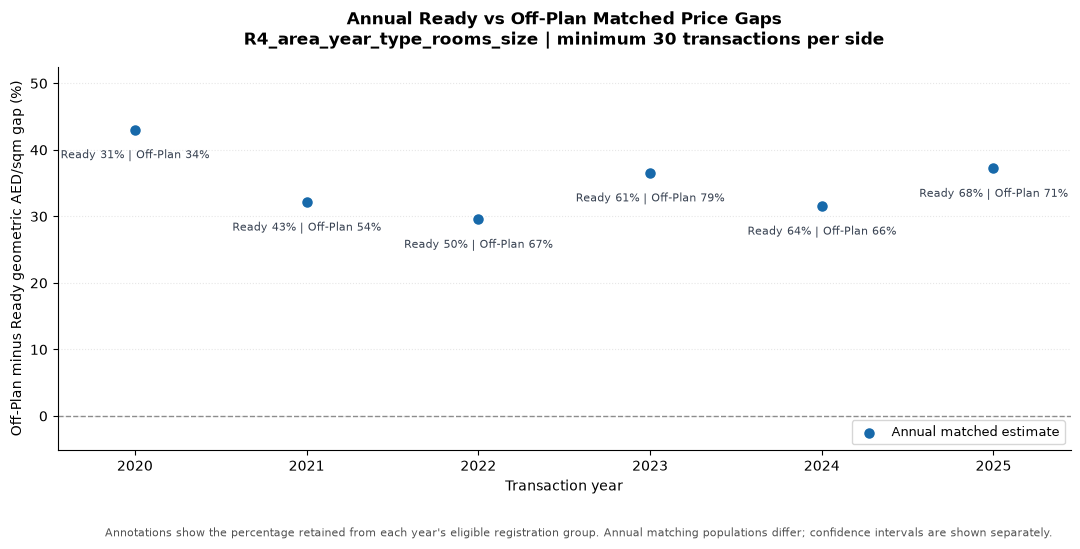

,strata,ready_n,offplan_n,effective_strata,largest_weight_pct,log_gap,gap_pct,median_log_gap,median_gap_pct,weight_mode,year,design,ready_parent_n,offplan_parent_n,ready_coverage_pct,offplan_coverage_pct,communities,comparability
0,35,4079,4426,24.735750,7.501470,0.357803,43.018398,0.364522,43.982621,pooled,2020,R4_area_year_type_rooms_size,13144,12993,31.033171,34.064496,14,Year-specific common support; target baskets d...
1,68,10517,11790,39.617922,6.307437,0.278620,32.130453,0.279709,32.274465,pooled,2021,R4_area_year_type_rooms_size,24648,21654,42.668776,54.447215,23,Year-specific common support; target baskets d...
2,95,16540,27077,52.686235,4.305661,0.258888,29.548903,0.271146,31.146708,pooled,2022,R4_area_year_type_rooms_size,33262,40153,49.726415,67.434563,23,Year-specific common support; target baskets d...
3,142,25837,50849,60.005688,5.119579,0.311347,36.526240,0.334026,39.657963,pooled,2023,R4_area_year_type_rooms_size,42392,64251,60.947820,79.141181,31,Year-specific common support; target baskets d...
4,166,30968,68834,67.948142,6.067013,0.274084,31.532579,0.282927,32.700830,pooled,2024,R4_area_year_type_rooms_size,48526,104074,63.817335,66.139478,34,Year-specific common support; target baskets d...
5,187,34154,90873,72.329982,5.445224,0.316368,37.213552,0.318670,37.529727,pooled,2025,R4_area_year_type_rooms_size,50400,128562,67.765873,70.684184,38,Year-specific common support; target baskets d...


In [44]:

# RQ11 — Annual Ready vs Off-Plan matched price gaps
# Descriptive annual estimates; uncertainty is shown separately.
# Each year uses its own common-support population.

registration_gap_yearly = []

if SELECTED_REG:
    for yr in range(BASE_YEAR, END_YEAR + 1):
        sub = REG_WINDOW.loc[REG_WINDOW.year.eq(yr)]

        est, detail = contemporaneous_gap(
            sub,
            REG_DESIGNS[SELECTED_REG],
            PRIMARY_MIN_N
        )

        if est:
            ready_parent = int(
                (sub.reg_type_label == "Ready").sum()
            )
            offplan_parent = int(
                (sub.reg_type_label == "Off-Plan").sum()
            )

            est.update(
                year=yr,
                design=SELECTED_REG,
                ready_parent_n=ready_parent,
                offplan_parent_n=offplan_parent,
                ready_coverage_pct=ratio_coverage(
                    est["ready_n"], ready_parent
                ),
                offplan_coverage_pct=ratio_coverage(
                    est["offplan_n"], offplan_parent
                ),
                communities=(
                    int(detail.area_key.nunique())
                    if "area_key" in detail.columns
                    else np.nan
                ),
                comparability=(
                    "Year-specific common support; "
                    "target baskets differ"
                )
            )

            registration_gap_yearly.append(est)

registration_gap_yearly = (
    pd.DataFrame(registration_gap_yearly)
    if registration_gap_yearly
    else pd.DataFrame(
        columns=["year", "gap_pct", "ready_n", "offplan_n"]
    )
)

# ----------------------------
# Visualization
# ----------------------------

fig, ax = plt.subplots(figsize=(11, 5.5))

if not registration_gap_yearly.empty:
    plot_df = (
        registration_gap_yearly
        .sort_values("year")
        .copy()
    )

    x = plot_df["year"].to_numpy(dtype=float)
    y = plot_df["gap_pct"].to_numpy(dtype=float)

    ax.scatter(
        x, y,
        s=75,
        color="#1769AA",
        edgecolors="white",
        linewidths=1.1,
        zorder=3,
        label="Annual matched estimate"
    )

    # Expand limits to accommodate annotations.
    ymin = min(0.0, float(np.nanmin(y)))
    ymax = max(0.0, float(np.nanmax(y)))
    span = max(ymax - ymin, 10.0)

    ax.set_ylim(
        ymin - 0.12 * span,
        ymax + 0.22 * span
    )

    ax.set_xlim(
        float(np.nanmin(x)) - 0.45,
        float(np.nanmax(x)) + 0.45
    )

    # Put annotations below high points and above
    # other points to avoid clipping and crowding.
    midpoint = (ymin + ymax) / 2

    for row in plot_df.itertuples(index=False):
        if not (
            np.isfinite(row.ready_coverage_pct)
            and np.isfinite(row.offplan_coverage_pct)
        ):
            continue

        is_high = row.gap_pct > midpoint

        offset = (0, -14) if is_high else (0, 12)
        vertical_alignment = "top" if is_high else "bottom"

        annotation = (
            f"Ready {row.ready_coverage_pct:.0f}%"
            f" | Off-Plan {row.offplan_coverage_pct:.0f}%"
        )

        ax.annotate(
            annotation,
            xy=(row.year, row.gap_pct),
            xytext=offset,
            textcoords="offset points",
            ha="center",
            va=vertical_alignment,
            fontsize=8,
            color="#374151"
        )

    ax.set_xticks(plot_df["year"].astype(int).tolist())
    ax.legend(loc="lower right", fontsize=9)

else:
    ax.text(
        0.5, 0.5,
        "No annual comparisons meet the matching criteria",
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=11
    )

ax.axhline(
    0,
    color="#737373",
    linewidth=1,
    linestyle="--",
    alpha=0.8
)

ax.set_title(
    "Annual Ready vs Off-Plan Matched Price Gaps\n"
    f"{SELECTED_REG or 'No eligible design'} | "
    f"minimum {PRIMARY_MIN_N} transactions per side",
    fontsize=12,
    weight="bold",
    pad=16
)

ax.set_xlabel("Transaction year")
ax.set_ylabel(
    "Off-Plan minus Ready geometric AED/sqm gap (%)"
)

ax.grid(
    axis="y",
    linestyle=":",
    alpha=0.30
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.10, 0.015,
    "Annotations show the percentage retained from "
    "each year's eligible registration group. "
    "Annual matching populations differ; "
    "confidence intervals are shown separately.",
    fontsize=8,
    color="#525252"
)

fig.tight_layout(rect=[0, 0.065, 1, 1])

fig.savefig(
    FIG / "05_registration_gap_yearly.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

display(registration_gap_yearly)


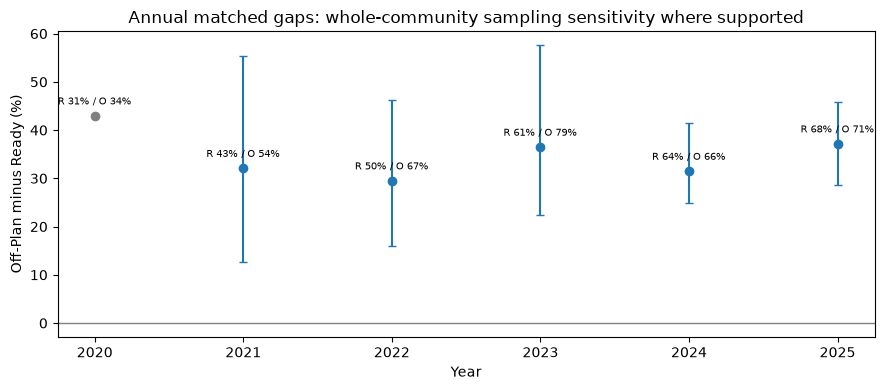

,year,communities,ci_low_pct,ci_high_pct,method
0,2020,14,NaN,NaN,WITHHELD; insufficient communities
1,2021,23,12.757647,55.465864,Whole-community resampling; year-specific supp...
2,2022,23,16.024558,46.229569,Whole-community resampling; year-specific supp...
3,2023,31,22.321326,57.596629,Whole-community resampling; year-specific supp...
4,2024,34,24.934102,41.573691,Whole-community resampling; year-specific supp...
5,2025,38,28.673378,45.919421,Whole-community resampling; year-specific supp...


In [45]:
# Annual community-level resampling, within each year's supported matched strata.
# If too few independent communities, intervals remain unavailable (not zero-width).
registration_gap_yearly_uncertainty=[]
if SELECTED_REG:
    for year in range(BASE_YEAR,END_YEAR+1):
        sub=REG_WINDOW.loc[REG_WINDOW.year.eq(year)]
        est,detail=contemporaneous_gap(sub,REG_DESIGNS[SELECTED_REG],PRIMARY_MIN_N)
        if est is None or detail.empty or 'area_key' not in detail:continue
        detail=detail.copy();detail['mass']=detail.ready_n+detail.offplan_n
        detail['num']=detail.mass*detail.mean_log_gap
        ag=detail.groupby('area_key',observed=True)[['mass','num']].sum()
        G=len(ag)
        if G<MIN_CLUSTER_COMMUNITIES:
            registration_gap_yearly_uncertainty.append(dict(year=year,communities=G,ci_low_pct=np.nan,ci_high_pct=np.nan,method='WITHHELD; insufficient communities'))
            continue
        masses=ag.mass.to_numpy(dtype=float);num=ag.num.to_numpy(dtype=float)
        sample_rng=np.random.default_rng(SEED+year)
        draw_ids=sample_rng.integers(0,G,size=(400,G))
        draw=num[draw_ids].sum(axis=1)/masses[draw_ids].sum(axis=1)
        lo,hi=np.quantile(draw,[.025,.975])
        registration_gap_yearly_uncertainty.append(dict(year=year,communities=G,
         ci_low_pct=float(100*np.expm1(lo)),ci_high_pct=float(100*np.expm1(hi)),
         method='Whole-community resampling; year-specific supported strata'))
registration_gap_yearly_uncertainty=pd.DataFrame(registration_gap_yearly_uncertainty)
if not registration_gap_yearly.empty:
    registration_gap_yearly=registration_gap_yearly.merge(registration_gap_yearly_uncertainty,
        on='year',how='left',validate='one_to_one') if not registration_gap_yearly_uncertainty.empty else registration_gap_yearly
fig,ax=plt.subplots(figsize=(9,4))
if not registration_gap_yearly.empty:
    for z in registration_gap_yearly.itertuples(index=False):
        low=getattr(z,'ci_low_pct',np.nan);hi=getattr(z,'ci_high_pct',np.nan)
        if np.isfinite(low) and np.isfinite(hi):
            ax.errorbar([z.year],[z.gap_pct],yerr=[[max(0,z.gap_pct-low)],[max(0,hi-z.gap_pct)]],fmt='o',capsize=3,color='tab:blue')
        else:ax.scatter(z.year,z.gap_pct,color='gray')
        ax.annotate(f'R {z.ready_coverage_pct:.0f}% / O {z.offplan_coverage_pct:.0f}%',(z.year,z.gap_pct),xytext=(0,8),textcoords='offset points',ha='center',fontsize=7)
ax.axhline(0,color='gray',lw=1)
ax.set(title='Annual matched gaps: whole-community sampling sensitivity where supported',xlabel='Year',ylabel='Off-Plan minus Ready (%)')
fig.tight_layout();fig.savefig(FIG/'05_registration_gap_yearly_cluster_sensitivity.png',dpi=140);plt.show()
display(registration_gap_yearly_uncertainty)

In [46]:
attribute_temporal_stability=[]
for typ,x in SIZE_FRAMES.items():
 for lo,hi in [(2015,2019),(2020,2022),(2023,2025)]:
  z=within_size_fit(x.loc[x.year.between(lo,hi)])
  if z:attribute_temporal_stability.append(dict(property_type_label=typ,start=lo,end=hi,**z))
attribute_temporal_stability=pd.DataFrame(attribute_temporal_stability) if attribute_temporal_stability else pd.DataFrame(columns=['property_type_label','start','end','beta'])
display(attribute_temporal_stability)

,property_type_label,start,end,beta,se_hc0,se_cluster,n,communities,within_ss,group_count,rmse,outcome
0,Unit,2015,2019,0.861647,0.001927,0.021576,125489,57,23732.821284,420,0.221234,log_price
1,Unit,2020,2022,0.946456,0.002086,0.023656,117436,61,24861.130484,292,0.258293,log_price
2,Unit,2023,2025,0.900162,0.000976,0.022026,389668,70,77363.647383,337,0.210786,log_price
3,Villa,2015,2019,0.699229,0.007435,0.049521,27596,91,3910.388126,421,0.231892,log_price
4,Villa,2020,2022,0.678004,0.004982,0.040499,28418,89,4439.104977,266,0.203449,log_price
5,Villa,2023,2025,0.707611,0.004206,0.041764,48537,94,8269.692992,296,0.211405,log_price


In [47]:
distributional_sensitivity=[]
for typ,frame in SIZE_FRAMES.items():
    for trimcol in ['log_price','log_area']:
        q=frame[trimcol].quantile([.01,.99])
        trimmed=frame.loc[frame[trimcol].between(float(q.iloc[0]),float(q.iloc[1]))]
        z=within_size_fit(trimmed)
        if z:distributional_sensitivity.append(dict(property_type_label=typ,policy=f'trim_{trimcol}_1_99pct',**z))
    price_q=frame.log_price.quantile([.01,.99]);area_q=frame.log_area.quantile([.01,.99])
    jointly=frame.loc[frame.log_price.between(*price_q.to_numpy()) & frame.log_area.between(*area_q.to_numpy())]
    z=within_size_fit(jointly)
    if z:distributional_sensitivity.append(dict(property_type_label=typ,policy='joint_price_area_1_99pct',**z))
    z=within_size_fit(frame)
    if z:distributional_sensitivity.append(dict(property_type_label=typ,policy='full',**z))
distributional_sensitivity=pd.DataFrame(distributional_sensitivity)
attribute_model_robustness=distributional_sensitivity.copy()
annual_ci_count=(int(registration_gap_yearly_uncertainty.ci_low_pct.notna().sum())
                 if not registration_gap_yearly_uncertainty.empty else 0)
annual_uncertain=int(len(registration_gap_yearly))-annual_ci_count
# Period-specific overlap differs; this is not a formal cross-year equality test.
temporal_decisions=pd.DataFrame([
 dict(claim='Annual registration gap',
      decision='QUALIFIED' if annual_ci_count>=3 else 'INCONCLUSIVE',
      restriction=f'{annual_ci_count} years with conditional whole-community sensitivity intervals; '
                  f'{annual_uncertain} without eligible community inference; year-specific changing common support'),
 dict(claim='Price–area elasticity by period',
      decision='QUALIFIED' if len(attribute_temporal_stability)>=4 else 'INCONCLUSIVE',
      restriction='Different observed populations by period; contrasts not a causal temporal change')])
display(distributional_sensitivity,temporal_decisions)


,property_type_label,policy,beta,se_hc0,se_cluster,n,communities,within_ss,group_count,rmse,outcome
0,Unit,trim_log_price_1_99pct,0.867148,0.000731,0.019885,620315,70,112016.471381,1044,0.216014,log_price
1,Unit,trim_log_area_1_99pct,0.886457,0.000749,0.020298,619949,70,106759.223178,1045,0.218458,log_price
2,Unit,joint_price_area_1_99pct,0.871650,0.000730,0.019790,611788,70,103326.610187,1043,0.214830,log_price
3,Unit,full,0.902042,0.000817,0.020049,632593,70,125957.599150,1049,0.222716,log_price
4,Villa,trim_log_price_1_99pct,0.618588,0.002289,0.030935,102489,98,13822.553479,955,0.195970,log_price
5,Villa,trim_log_area_1_99pct,0.649129,0.002642,0.036383,102691,96,13874.029143,937,0.207486,log_price
6,Villa,joint_price_area_1_99pct,0.610031,0.002328,0.031209,101708,95,13008.730669,921,0.194943,log_price
7,Villa,full,0.697731,0.003042,0.035996,104551,101,16619.186095,983,0.214980,log_price


,claim,decision,restriction
0,Annual registration gap,QUALIFIED,5 years with conditional whole-community sensi...
1,Price–area elasticity by period,QUALIFIED,Different observed populations by period; cont...


## 09. Robustness, conditional uncertainty, and acceptance
Separate changes in **population** from changes in the **estimator**. Bootstrap intervals are conditional on sampled transactions/selected groups and need not account for correlated project sales. Use community-level cluster sensitivity only when sufficient identifying communities exist. No p-value alone is an acceptance criterion.

In [48]:
# Conditional within-stratum bootstrap for the contemporaneous mean-log gap.
REG_BOOT_REPS=300
registration_gap_uncertainty=pd.DataFrame(columns=['design','replicates','ci_low_pct','ci_high_pct','conditional_se_log','population'])
if SELECTED_REG and len(reg_matched):
 keys=REG_DESIGNS[SELECTED_REG]
 groups=[]
 for _,g in reg_matched.groupby(keys,observed=True,sort=True):
  a=g.loc[g.reg_type_label.eq('Ready'),'log_psm'].to_numpy(dtype=float)
  b=g.loc[g.reg_type_label.eq('Off-Plan'),'log_psm'].to_numpy(dtype=float)
  groups.append((a,b,len(a)+len(b)))
 ww=np.array([z[2] for z in groups],dtype=float);ww/=ww.sum()
 rng=np.random.default_rng(SEED+1);sims=np.zeros(REG_BOOT_REPS)
 for k in range(REG_BOOT_REPS):
  differences=[rng.choice(b,size=len(b),replace=True).mean()-rng.choice(a,size=len(a),replace=True).mean() for a,b,_ in groups]
  sims[k]=np.dot(ww,differences)
 lo,hi=np.quantile(sims,[.025,.975])
 registration_gap_uncertainty=pd.DataFrame([dict(design=SELECTED_REG,replicates=REG_BOOT_REPS,ci_low_pct=100*np.expm1(lo),ci_high_pct=100*np.expm1(hi),conditional_se_log=float(sims.std(ddof=1)),population='Fixed group support/weights, independent transaction resampling')])
display(registration_gap_uncertainty)

,design,replicates,ci_low_pct,ci_high_pct,conditional_se_log,population
0,R4_area_year_type_rooms_size,300,34.221863,34.694227,0.000926,"Fixed group support/weights, independent trans..."


In [49]:
# Synthetic weighted-cluster estimator identity with deliberately unequal community masses.
_synthetic_agg=pd.DataFrame({'mass':[10.,20.,30.],'weighted_delta_sum':[1.,4.,9.]})
expected=(1+4+9)/60
assert np.isclose(_synthetic_agg.weighted_delta_sum.sum()/_synthetic_agg.mass.sum(),expected)
# With a constant stratum gap, community resampling cannot create artificial spread.
_constant_num=_synthetic_agg.mass.to_numpy()*.2
for _idx in [[0,0,1],[2,2,2],[0,1,2]]:
    assert np.isclose(_constant_num[_idx].sum()/_synthetic_agg.mass.to_numpy()[_idx].sum(),.2)
print('Cluster-weighting and constant-gap synthetic identities PASS')

Cluster-weighting and constant-gap synthetic identities PASS


In [50]:
# Community-level sampling sensitivity for PRIMARY pooled-weight matched estimand.
# Unlike a transaction bootstrap, this resamples whole communities; no claim of
# causal or unconditional Dubai-population confidence is permitted.
REG_CLUSTER_REPS=600
registration_cluster_uncertainty=pd.DataFrame(columns=['design','clusters','replicates','ci_low_pct','ci_high_pct','cluster_se_log','method','restriction'])
if SELECTED_REG and not offplan_ready_stratum_detail.empty:
    detail=offplan_ready_stratum_detail.copy()
    assert 'area_key' in detail and detail.area_key.notna().all()
    detail['mass']=detail.ready_n+detail.offplan_n
    detail['weighted_delta_sum']=detail.mass*detail.mean_log_gap
    agg=detail.groupby('area_key',observed=True)[['mass','weighted_delta_sum']].sum().reset_index()
    G=len(agg)
    direct=float(agg.weighted_delta_sum.sum()/agg.mass.sum())
    assert np.isclose(direct,reg_primary['log_gap'],atol=1e-11)
    if G>=MIN_CLUSTER_COMMUNITIES:
        m=agg.mass.to_numpy(dtype=float);numer=agg.weighted_delta_sum.to_numpy(dtype=float)
        rng_cluster=np.random.default_rng(SEED+17)
        samples=rng_cluster.integers(0,G,size=(REG_CLUSTER_REPS,G))
        draws=numer[samples].sum(axis=1)/m[samples].sum(axis=1)
        assert np.isfinite(draws).all()
        lo,hi=np.quantile(draws,[.025,.975]);jack=(numer.sum()-numer)/(m.sum()-m)
        jack_se=float(np.sqrt((G-1)/G*((jack-jack.mean())**2).sum()))
        registration_cluster_uncertainty=pd.DataFrame([dict(design=SELECTED_REG,clusters=G,replicates=REG_CLUSTER_REPS,
          ci_low_pct=float(100*np.expm1(lo)),ci_high_pct=float(100*np.expm1(hi)),
          cluster_se_log=float(draws.std(ddof=1)),jackknife_se_log=jack_se,
          method='whole-community pairs bootstrap, reweighted fixed matched strata',
          restriction='Community sampling sensitivity, fixed matched support; not an unconditional causal or market-wide interval')])
display(registration_cluster_uncertainty)

,design,clusters,replicates,ci_low_pct,ci_high_pct,cluster_se_log,jackknife_se_log,method,restriction
0,R4_area_year_type_rooms_size,43,600,25.835423,45.25571,0.038902,0.041855,"whole-community pairs bootstrap, reweighted fi...","Community sampling sensitivity, fixed matched ..."


In [51]:
registration_gap_robustness=[]
for design in REG_DESIGNS:
 for threshold in THRESHOLDS:
  for weight_mode in ['pooled','ready','offplan','equal']:
   est,_=contemporaneous_gap(DESIGN_FRAMES[design],REG_DESIGNS[design],threshold,weight_mode)
   if est:
    registration_gap_robustness.append(dict(design=design,min_cell_n=threshold,**est))
registration_gap_robustness=pd.DataFrame(registration_gap_robustness) if registration_gap_robustness else pd.DataFrame(columns=['design','min_cell_n','weight_mode','gap_pct'])
attribute_model_robustness=distributional_sensitivity.copy()
display(registration_gap_robustness.query('min_cell_n==30 and weight_mode=="pooled"') if len(registration_gap_robustness) else registration_gap_robustness)

,design,min_cell_n,strata,ready_n,offplan_n,effective_strata,largest_weight_pct,log_gap,gap_pct,median_log_gap,median_gap_pct,weight_mode
4,R0_type_year,30,12,212372,371687,5.711480,27.963271,0.350384,41.961244,0.361340,43.525129,pooled
16,R1_area_year_type,30,261,179130,331329,100.021569,3.403995,0.311526,36.550776,0.316620,37.248077,pooled
28,R2_area_year_type_size,30,663,142409,281433,286.975926,1.635043,0.305227,35.693240,0.314423,36.946951,pooled
40,R3_area_year_type_rooms,30,553,152048,303707,220.296362,2.009194,0.312703,36.711594,0.319669,37.667166,pooled
52,R4_area_year_type_rooms_size,30,693,122095,253849,275.879845,1.810908,0.296148,34.466852,0.305525,35.733808,pooled
64,R5_area_quarter_type_rooms_size,30,927,78267,172329,511.742235,0.855959,0.291750,33.876893,0.297613,34.664051,pooled


In [52]:
# Core-vs-Strict matching sensitivity on PREDEFINED design; denominators differ.
quality_sensitivity=[]
if SELECTED_REG:
 cw=core.loc[core.year.between(BASE_YEAR,END_YEAR)&core.reg_type_label.isin(['Ready','Off-Plan'])].copy()
 ss,_=contemporaneous_gap(cw,REG_DESIGNS[SELECTED_REG],PRIMARY_MIN_N)
 quality_sensitivity.append(dict(design=SELECTED_REG,strict_pct=reg_primary['gap_pct'],core_pct=ss['gap_pct'] if ss else np.nan,core_minus_strict_pp=(ss['gap_pct']-reg_primary['gap_pct']) if ss else np.nan,core_n=len(cw),strict_n=len(REG_WINDOW)))
quality_sensitivity=pd.DataFrame(quality_sensitivity) if quality_sensitivity else pd.DataFrame(columns=['design','strict_pct','core_pct','core_minus_strict_pp'])
model_missingness_robustness=pd.concat([attribute_selection_bias.assign(test='observed_missingness'),quality_sensitivity.assign(test='quality_policy')],ignore_index=True)
display(quality_sensitivity)

,design,strict_pct,core_pct,core_minus_strict_pp,core_n,strict_n
0,R4_area_year_type_rooms_size,34.466852,35.4311,0.964247,594290,584059


### Final decision gate refinement — observational stability, not causal proof

RQ11 can remain **QUALIFIED** only if matched registration overlap, community-cluster inference,
full-community leave-out sign stability and a dependence-aware sensitivity interval excluding
zero all hold. A material leave-one-community-out movement is always reported, regardless of
whether the sign changes. **This is a conservative exploratory decision, not a preregistered
hypothesis test and not a market-wide claim.** The fixed-strata community bootstrap conditions
on the selected support and does not resolve missing-bedroom, project or contract-selection bias.

RQ10 must pass the mechanical AED/sqm identity and produce identifiable, cluster-aware nonlinear
fits; trimming-sensitivity sign reversals trigger **INCONCLUSIVE**. The magnitude of coefficient
shifts remains prominently recorded, even if the sign is stable. The 1% trimming policies are
sensitivity specifications, not objective quality exclusions. Bedroom contrasts must pass both
community-year category co-occurrence and overlap in their central 10–90% area ranges;
unsupported category contrasts are withheld without re-fitting the global regression.


In [53]:
# FINAL outcome-independent rules: no post-hoc magnitude cutoff masquerades as prespecified.
# Robustness failures: sign reversal across community deletions, or dependence-aware interval
# includes zero -> INCONCLUSIVE; otherwise QUALIFIED with observed max influence disclosed.
if SELECTED_REG:
    G=int(reg_matched.area_key.nunique())
    cluster_ok=not registration_cluster_uncertainty.empty and G>=MIN_CLUSTER_COMMUNITIES
    fe_ok=not registration_regression.empty and registration_regression.se_cluster.notna().all()
    coverage_ok=bool((registration_matching_coverage.coverage_pct>=MIN_OVERLAP_EACH_SIDE_PCT).all())
    shifts=geographic_heterogeneity.delta_from_main_pp.dropna() if not geographic_heterogeneity.empty else pd.Series(dtype=float)
    risk=float(shifts.abs().max()) if len(shifts) else np.inf
    loo=geographic_heterogeneity.gap_pct.dropna() if not geographic_heterogeneity.empty else pd.Series(dtype=float)
    sign_consistent=bool(len(loo)==G and (np.sign(np.expm1(geographic_heterogeneity.log_gap.dropna()))==np.sign(reg_primary['log_gap'])).all())
    interval_excludes_zero=(cluster_ok and not (registration_cluster_uncertainty.ci_low_pct.iloc[0]<=0<=registration_cluster_uncertainty.ci_high_pct.iloc[0]))
    decision_r11='QUALIFIED' if (cluster_ok and fe_ok and coverage_ok and sign_consistent and interval_excludes_zero) else 'INCONCLUSIVE'
    rq11_decision.loc[0,'decision']=decision_r11
    rq11_decision.loc[0,'restriction']=(f'Overlap-only observational contrast; dependence-sensitive interval '
       f'{"excludes" if interval_excludes_zero else "does not establish exclusion of"} zero; '
       f'largest leave-community-out change {risk:.2f} percentage points; '
       'community influence, selective attrition, project and registration-process differences remain')
else:
    rq11_decision.loc[0,'decision']='NOT ESTIMABLE'
# RQ10: check algebra, covariance and sign stability under all documented trims.
if not size_price_linear_models.empty and not distributional_sensitivity.empty:
    shifts=[];reversals=[];missing_trims=[]
    for typ in size_price_linear_models.property_type_label.unique():
        s=distributional_sensitivity.loc[distributional_sensitivity.property_type_label.eq(typ)]
        full=s.loc[s.policy.eq('full'),'beta']
        others=s.loc[~s.policy.eq('full'),'beta']
        if len(full)!=1 or len(others)<3:
            missing_trims.append(typ);continue
        shifts.append(float((others-full.iloc[0]).abs().max()))
        reversals.append(bool((np.sign(others)!=np.sign(float(full.iloc[0]))).any()))
    max_shift=max(shifts) if shifts else np.inf
    nonlin_inference=(not size_price_nonlinear_models.empty and size_price_nonlinear_models.se_hinge.notna().all())
    valid_identity=bool(size_denominator_identity.passed.all())
    rq10_pass=valid_identity and nonlin_inference and not missing_trims and not any(reversals) and np.isfinite(max_shift)
    rq10_decision.loc[0,'decision']='QUALIFIED' if rq10_pass else 'INCONCLUSIVE'
    rq10_decision.loc[0,'restriction']=(f'Cross-sectional area association, NOT enlargement effect; maximum absolute trimming '
      f'elasticity shift {max_shift:.4f}; sign reversals {sum(reversals)}; missing trimming sets {missing_trims}; '
      f'nonlinear clustered inference {"available" if nonlin_inference else "withheld"}; '
      'model dependence and omitted quality remain, especially for Villas')
if bedroom_meta.get('status')=='BLOCKED':
    rq12_decisions.loc[rq12_decisions.rq.eq('RQ12_bedrooms'),'decision']='BLOCKED'
if bedroom_meta.get('status')=='QUALIFIED':
    assert not bedroom_adjusted.empty and bedroom_adjusted.se_cluster.notna().all()
    # The global RQ12 claim remains INCONCLUSIVE if no category cleared area overlap.
    if bedroom_contrast_support.empty or not bedroom_contrast_support.decision.eq('QUALIFIED').any():
        rq12_decisions.loc[rq12_decisions.rq.eq('RQ12_bedrooms'),'decision']='INCONCLUSIVE'
print('Final claim gates:',rq11_decision.decision.iloc[0],rq10_decision.decision.iloc[0],rq12_decisions.decision.tolist())


Final claim gates: QUALIFIED QUALIFIED ['QUALIFIED', 'NOT ESTIMABLE']


In [54]:
# Decisions apply per question, never a global green light.
research_decisions=pd.concat([rq11_decision.assign(claim='Ready–Off-Plan adjusted gap'),rq10_decision.assign(claim='Price–area structure'),rq12_decisions.assign(claim=rq12_decisions.rq)],ignore_index=True,sort=False)
assert research_decisions.decision.isin(['SUPPORTED','QUALIFIED','INCONCLUSIVE','NOT ESTIMABLE','BLOCKED']).all()
assert research_decisions.rq.is_unique
display(research_decisions[['rq','claim','decision','restriction']])

,rq,claim,decision,restriction
0,RQ11,Ready–Off-Plan adjusted gap,QUALIFIED,Overlap-only observational contrast; dependenc...
1,RQ10,Price–area structure,QUALIFIED,"Cross-sectional area association, NOT enlargem..."
2,RQ12_bedrooms,RQ12_bedrooms,QUALIFIED,2 category contrasts with >=10 communities mee...
3,RQ12_parking,RQ12_parking,NOT ESTIMABLE,Recorded parking is confounded with unobserved...


## 10. Independent validation, research exports and conclusions
All accepted research artifacts must reconcile to their declared population. Non-estimable results may be absent from estimate tables, but must be **present in the decision registry**. The final findings are computed dynamically; the notebook never hardcodes the sign or magnitude of a price gap.

In [55]:
VALIDATION=[]
def check(name,ok,detail=''):
 good=bool(ok);VALIDATION.append(dict(check=name,passed=good,detail=str(detail)))
 if not good:raise AssertionError(f'Notebook 05 validation FAILED: {name}: {detail}')
check('Pinned source SHA',source.sha256==SNAPSHOT_SHA256)
check('Source structural validation',validation.passed)
check('Source rows unchanged',len(raw)==len(f) and all(raw[c].equals(f[c]) for c in raw.columns))
check('Historical source 2026 excluded',p0.year.between(2010,2025).all())
check('P0 transaction uniqueness',p0.transaction_id.is_unique)
check('P1 Core subset',set(p1_core.transaction_id).issubset(set(p0.transaction_id)))
check('P1 Strict subset Core',set(p1.transaction_id).issubset(set(p1_core.transaction_id)))
check('P2 subset Strict',set(p2.transaction_id).issubset(set(p1.transaction_id)))
check('P3 subset Strict',set(p3.transaction_id).issubset(set(p1.transaction_id)))
check('P1 prices/area positive',p1.price_per_sqm.gt(0).all() and p1.area_sqm.gt(0).all())
check('Model price/area identity',np.allclose(r.log_price-r.log_area,r.log_psm))
check('P1 annual structure reconciles',int(residential_structure.n.sum())==len(r))
check('Registration procedures reconcile',int(procedure_diagnostics.n.sum())==len(r))
check('Attribute selection reconciles', (attribute_selection_bias.known_n+attribute_selection_bias.missing_n==attribute_selection_bias.parent_n).all())
check('Registration feasibility rows',len(registration_overlap_feasibility)==len(REG_DESIGNS)*len(THRESHOLDS))
check('Selection support-only',SELECTED_REG is None or support_ok(SELECTED_REG))
check('Matching no duplications',reg_matched.transaction_id.is_unique)
check('Matched counts bounded',(registration_matching_coverage.matched_n<=registration_matching_coverage.parent_n).all())
check('Matched counts partition',registration_matching_coverage.matched_n.sum()==len(reg_matched))
check('Every parent registration represented',registration_matching_coverage.reg_type_label.tolist()==['Ready','Off-Plan'])
check('Matching coverage arithmetic',all(np.isclose(z.coverage_pct,ratio_coverage(z.matched_n,z.parent_n),equal_nan=True) for z in registration_matching_coverage.itertuples(index=False)))
check('No selection-dependent estimate fabricated',SELECTED_REG is not None or offplan_ready_matched_gap.empty)
check('Selected weights normalized',SELECTED_REG is None or np.isclose(selected_counts.weight.sum(),1))
check('Selected groups supported',SELECTED_REG is None or (selected_counts.Ready.ge(PRIMARY_MIN_N)&selected_counts['Off-Plan'].ge(PRIMARY_MIN_N)).all())
check('Adjusted contrast reconstructed',SELECTED_REG is None or np.isclose(offplan_ready_stratum_detail.contribution.sum(),offplan_ready_matched_gap.log_gap.iloc[0]))
check('Log gap percent arithmetic',SELECTED_REG is None or np.isclose(100*np.expm1(offplan_ready_matched_gap.log_gap.iloc[0]),offplan_ready_matched_gap.gap_pct.iloc[0]))
check('Primary sample observation reconciliation',SELECTED_REG is None or len(reg_matched)==reg_primary['ready_n']+reg_primary['offplan_n'])
check('FE regression supported',registration_regression.empty or registration_regression.identified.all())
check('Size regression available',not size_price_linear_models.empty)
check('Size mathematical identity',not size_denominator_identity.empty and size_denominator_identity.passed.all())
check('Size model rows nonnegative',(size_price_linear_models.n>0).all())
check('Unknown bedrooms not imputed',r.rooms_bucket.isna().sum()==AMENITY_PARENT.rooms_bucket.isna().sum()+r.loc[~((r.property_type_label=='Unit')&(r.reg_type_label=='Ready'))].rooms_bucket.isna().sum())
check('Amenity cohort original P3 membership',AMENITY_KNOWN.transaction_id.isin(p3.transaction_id).all())
check('Parking sample positive',len(p)==len(AMENITY_KNOWN))
check('Parking overlaps valid',(parking_support.positive+parking_support.negative==parking_support.n).all())
check('No unsupported parking estimate',parking_associations.empty or parking_overlap_feasibility.overlap_cells.iloc[0]>=10)
check('No unsupported historical periods',registration_gap_yearly.empty or registration_gap_yearly.year.between(BASE_YEAR,END_YEAR).all())
check('Bootstrap replicate validity',registration_gap_uncertainty.empty or registration_gap_uncertainty.replicates.ge(100).all())
check('Bootstrap interval order',registration_gap_uncertainty.empty or registration_gap_uncertainty.ci_low_pct.le(registration_gap_uncertainty.ci_high_pct).all())
check('Decision completeness',set(research_decisions.rq)=={'RQ11','RQ10','RQ12_bedrooms','RQ12_parking'})
check('No causal conclusions stored',not research_decisions.claim.str.contains('causal premium|returns',case=False).any())

check('Bedroom reference explicitly removed', bedroom_meta.get('status')!='QUALIFIED' or ('bed_1' not in bedroom_adjusted.term.tolist()))
check('Bedroom covariance established', bedroom_meta.get('status')!='QUALIFIED' or (bedroom_adjusted.se_cluster.notna().all() and bedroom_meta.get('communities',0)>=MIN_CLUSTER_COMMUNITIES))
check('Bedroom model not mislabeled on implementation failure', bedroom_meta.get('status')!='BLOCKED' or rq12_decisions.loc[rq12_decisions.rq.eq('RQ12_bedrooms'),'decision'].iloc[0]=='BLOCKED')
check('Matched geographic leave-out complete', SELECTED_REG is None or len(geographic_heterogeneity)==int(reg_matched.area_key.nunique()))
check('Segment-level retention reconciliation', (registration_segment_selection.parent_n==registration_segment_selection.matched_n+registration_segment_selection.missing_feature_n+registration_segment_selection.unmatched_after_feature_n).all())
check('Cluster-matched estimator label', registration_cluster_uncertainty.empty or registration_cluster_uncertainty.method.str.contains('whole-community').all())
check('Cluster-matched CI contains point or marked sensitivity', registration_cluster_uncertainty.empty or (registration_cluster_uncertainty.ci_low_pct.le(registration_cluster_uncertainty.ci_high_pct)).all())
check('Nonlinear model covariance valid', size_price_nonlinear_models.empty or (size_price_nonlinear_models.se_hinge.dropna().ge(0)).all())
check('Parking counts reconcile', parking_overlap_feasibility.empty or (parking_overlap_feasibility.parking_yes_n+parking_overlap_feasibility.parking_no_n==parking_overlap_feasibility.both_known_n).all())
check('Decision blocked on estimator defect', bedroom_meta.get('status')!='BLOCKED' or (rq12_decisions.loc[rq12_decisions.rq.eq('RQ12_bedrooms'),'decision'].iloc[0]=='BLOCKED'))


check('Bedroom pairwise support publication gate', bedroom_contrast_support.empty or (bedroom_adjusted.loc[bedroom_adjusted.decision.eq('INCONCLUSIVE'),'association_pct'].isna().all()))
check('Size joint interaction identified', size_interaction_joint.empty or (size_interaction_joint.se_difference.ge(0).all() and size_interaction_joint.communities.ge(MIN_CLUSTER_COMMUNITIES).all()))
check('Annual cluster interval order', registration_gap_yearly_uncertainty.empty or registration_gap_yearly_uncertainty.dropna(subset=['ci_low_pct','ci_high_pct']).eval('ci_low_pct <= ci_high_pct').all())
check('Bedroom area-support withholding', bedroom_contrast_support.empty or
      bedroom_adjusted.loc[bedroom_adjusted.decision.eq('INCONCLUSIVE'),'association_pct'].isna().all())
check('Bedroom area overlap metadata',bedroom_contrast_support.empty or
      (bedroom_contrast_support.area_overlap_communities<=bedroom_contrast_support.paired_communities).all())
check('Annual inference narration agrees with table',temporal_decisions.loc[temporal_decisions.claim.eq('Annual registration gap'),'restriction'].str.contains('whole-community').all())
check('RQ11 reported inference matches community interval', SELECTED_REG is None or
      rq11_decision.decision.iloc[0]!='QUALIFIED' or
      (not registration_cluster_uncertainty.empty and
       not (registration_cluster_uncertainty.ci_low_pct.iloc[0]<=0<=registration_cluster_uncertainty.ci_high_pct.iloc[0])))
check('RQ10 qualified without sign reversals',rq10_decision.decision.iloc[0]!='QUALIFIED' or not any(reversals))
research_validation=pd.DataFrame(VALIDATION)
display(research_validation)
print('Notebook 05 research audit:',int(research_validation.passed.sum()),'/',len(research_validation))


,check,passed,detail
0,Pinned source SHA,True,
1,Source structural validation,True,
2,Source rows unchanged,True,
3,Historical source 2026 excluded,True,
4,P0 transaction uniqueness,True,
5,P1 Core subset,True,
6,P1 Strict subset Core,True,
7,P2 subset Strict,True,
8,P3 subset Strict,True,
9,P1 prices/area positive,True,


Notebook 05 research audit: 59 / 59


In [56]:
# Export only validated, nonempty research results. Cross-format schema verification uses copies.
assert research_validation.passed.all()
EXPORTS={k:v for k,v in globals().copy().items() if isinstance(v,pd.DataFrame) and k in {
 'source_manifest','cohort_reconciliation','attribute_completeness','procedure_diagnostics','attribute_selection_bias','registration_overlap_feasibility','feasibility_gate','residential_structure','raw_registration_gaps','registration_mix_diagnostics','price_distribution_diagnostics','comparison_concentration','registration_matching_decision','registration_matched_cells','registration_unmatched_audit','registration_matching_coverage','offplan_ready_matched_gap','offplan_ready_stratum_detail','raw_matched_gap_comparison','registration_regression','registration_model_diagnostics','registration_gap_heterogeneity','rq11_decision','size_support','size_price_binned','size_price_linear_models','size_price_nonlinear_models','size_denominator_identity','size_interactions','rq10_decision','bedroom_support','selection_amenity','bedroom_descriptive','bedroom_adjusted','parking_overlap_feasibility','parking_associations','amenity_sensitivity','rq12_decisions','market_interactions','project_dependence','geographic_heterogeneity','interaction_decisions','registration_gap_yearly','attribute_temporal_stability','distributional_sensitivity','temporal_decisions','registration_gap_uncertainty','registration_gap_robustness','attribute_model_robustness','quality_sensitivity','model_missingness_robustness','research_decisions','research_validation','registration_segment_selection','matched_project_diagnostics','registration_cluster_uncertainty','bedroom_contrast_support','size_interaction_joint','registration_gap_yearly_uncertainty'}}
export_rows=[];skipped=[]
for name,frame in EXPORTS.items():
 if frame.empty:skipped.append(name);continue
 out=frame.copy();out.columns=[str(v) for v in out.columns]
 assert out.columns.is_unique
 csv=TABLES/('05_'+name+'.csv');pq=AGG/('05_'+name+'.parquet')
 out.to_csv(csv,index=False);out.to_parquet(pq,index=False,engine='pyarrow')
 a=pd.read_csv(csv);b=pd.read_parquet(pq,engine='pyarrow')
 assert len(out)==len(a)==len(b)
 assert list(a.columns)==list(b.columns)==list(out.columns)
 for field in out.select_dtypes(include='number').columns:
  assert np.allclose(pd.to_numeric(out[field],errors='coerce').to_numpy(dtype=float),pd.to_numeric(b[field],errors='coerce').to_numpy(dtype=float),equal_nan=True,rtol=1e-10,atol=1e-7),f'{name}.{field}'
 for field in out.columns:
  if field not in out.select_dtypes(include='number').columns:
   left=out[field].astype('string').fillna('<NULL>').to_numpy(dtype=str)
   right=b[field].astype('string').fillna('<NULL>').to_numpy(dtype=str)
   assert np.array_equal(left,right),f'{name}.{field}: nonnumeric parquet mismatch'
 export_rows.append(dict(name=name,rows=len(out),columns=len(out.columns),csv_bytes=csv.stat().st_size,parquet_bytes=pq.stat().st_size,source_sha256=source.sha256,verified=True))
export_manifest=pd.DataFrame(export_rows)
assert len(export_manifest)>=20
print('Verified CSV/Parquet research pairs:',len(export_manifest),' skipped unsupported:',len(skipped));display(export_manifest)


Verified CSV/Parquet research pairs: 58  skipped unsupported: 1


,name,rows,columns,csv_bytes,parquet_bytes,source_sha256,verified
0,source_manifest,1,9,270,6203,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
1,cohort_reconciliation,6,5,358,3699,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
2,attribute_completeness,264,7,13571,6708,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
3,procedure_diagnostics,270,6,14602,5725,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
4,attribute_selection_bias,88,12,8466,11111,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
5,registration_overlap_feasibility,18,15,3409,11433,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
6,feasibility_gate,3,5,520,4092,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
7,residential_structure,44,9,4044,8028,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
8,raw_registration_gaps,22,8,2232,6379,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True
9,registration_mix_diagnostics,1324,8,79499,30427,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True


In [57]:
# Plot index includes method/population caveats; figures generated in notebook cells.
figure_meta={
 '05_attribute_completeness.png':'P1 Strict Villa; observed attribute knownness',
 '05_raw_registration_gaps.png':'Raw registered transaction populations, not adjusted',
 '05_matching_support.png':'Both registration sides; P1 Strict denominator',
 '05_raw_vs_matched_gap.png':'Different populations and estimands',
 '05_size_price_binned.png':'Observed unconnected physical size-band medians; n>=30 and per-bin n labels',
 '05_bedroom_descriptive.png':'Raw Ready Unit bedroom categories',
 '05_registration_gap_yearly.png':'Annual point estimates; year-specific support; separate interval graphic follows',
 '05_size_piecewise_supported.png':'Within-FE conditional supported size ranges; mathematical price/area relationship',
 '05_registration_gap_yearly_cluster_sensitivity.png':'Community resampling uncertainty in separately supported year-specific strata',
}
visualization_manifest=pd.DataFrame([dict(figure=file,exists=(FIG/file).is_file(),bytes=(FIG/file).stat().st_size if (FIG/file).is_file() else 0,restriction=note) for file,note in figure_meta.items()])
assert visualization_manifest.exists.all()
display(visualization_manifest)


,figure,exists,bytes,restriction
0,05_attribute_completeness.png,True,47732,P1 Strict Villa; observed attribute knownness
1,05_raw_registration_gaps.png,True,61510,"Raw registered transaction populations, not ad..."
2,05_matching_support.png,True,57637,Both registration sides; P1 Strict denominator
3,05_raw_vs_matched_gap.png,True,31931,Different populations and estimands
4,05_size_price_binned.png,True,153155,Observed unconnected physical size-band median...
5,05_bedroom_descriptive.png,True,35756,Raw Ready Unit bedroom categories
6,05_registration_gap_yearly.png,True,96560,Annual point estimates; year-specific support;...
7,05_size_piecewise_supported.png,True,103554,Within-FE conditional supported size ranges; m...
8,05_registration_gap_yearly_cluster_sensitivity...,True,39340,Community resampling uncertainty in separately...


In [58]:
# All statements are composed AFTER finalized, independently gated decisions.
findings=[]
for row in research_decisions.itertuples(index=False):
    rq=row.rq;status=row.decision
    if rq=='RQ11':
        desc=(f'Observed {SELECTED_REG} strata: Off-Plan minus Ready {reg_primary["gap_pct"]:+.2f}% geometric-mean AED/sqm; '
              f'Ready {reg_primary["ready_n"]:,} and Off-Plan {reg_primary["offplan_n"]:,} matched observations. '
              f'Cluster-community sensitivity {"available" if not registration_cluster_uncertainty.empty else "not estimable"}.'
              if SELECTED_REG else 'No matching design satisfied the frozen two-sided support rules.')
    elif rq=='RQ10':
        desc='; '.join(f'{z.property_type_label}: observational within-group log-price area elasticity {z.beta:.3f}' for z in size_price_linear_models.query('outcome=="log_price"').itertuples(index=False))
    elif rq=='RQ12_bedrooms':
        if status=='BLOCKED':desc='Bedroom model blocked by implementation or covariance error; no market conclusion.'
        elif not bedroom_adjusted.empty:desc=f'Observed size-adjusted categorical-bedroom coefficients estimated for {bedroom_meta.get("n",0):,} Ready Units; unobserved quality remains.'
        else:desc='No identifiable or supported bedroom contrast under the prespecified model.'
    else:
        desc=('Observed recorded-parking association estimated within qualifying Ready Unit strata.' if not parking_associations.empty
              else 'Insufficient independently supported within-community/year parking variation; estimate withheld.')
    findings.append(dict(rq=rq,decision=status,interpretation=desc,restriction=row.restriction,source_sha256=source.sha256))
research_findings=pd.DataFrame(findings)
assert len(research_findings)==4 and research_findings.rq.is_unique
csv=TABLES/'05_research_findings.csv';parq=AGG/'05_research_findings.parquet'
research_findings.to_csv(csv,index=False);research_findings.to_parquet(parq,index=False,engine='pyarrow')
assert pd.read_parquet(parq,engine='pyarrow').equals(research_findings)
display(research_findings)
print('Validated checks:',len(research_validation),'| Table pairs including final findings:',len(export_manifest)+1)
print('NO causal registration, bedroom, parking, area or investment-effect claims. No inference to unsampled populations.')


,rq,decision,interpretation,restriction,source_sha256
0,RQ11,QUALIFIED,Observed R4_area_year_type_rooms_size strata: ...,Overlap-only observational contrast; dependenc...,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
1,RQ10,QUALIFIED,Unit: observational within-group log-price are...,"Cross-sectional area association, NOT enlargem...",8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
2,RQ12_bedrooms,QUALIFIED,Observed size-adjusted categorical-bedroom coe...,2 category contrasts with >=10 communities mee...,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
3,RQ12_parking,NOT ESTIMABLE,Insufficient independently supported within-co...,Recorded parking is confounded with unobserved...,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...


Validated checks: 59 | Table pairs including final findings: 59
NO causal registration, bedroom, parking, area or investment-effect claims. No inference to unsampled populations.
